# PLOTS

In [1]:
from pathlib import Path
import json
import pandas as pd

## PATH

In [2]:
#BASE_DIR = Path("/kaggle/input/datasets/eller01/results-300/results_300")

#EXPERIMENTS = {
#    "base_SAM": BASE_DIR / "300",
#    "filled": BASE_DIR / "300_filled",
#    "boosted": BASE_DIR / "300_boosted",
#    "boosted_filled": BASE_DIR / "300_boosted_filled",
#}

In [3]:
from pathlib import Path

BASE_DIR = Path(
    "/kaggle/input/datasets/eller01/results-300/results_300"
)

BOOSTED_1K_DIR = Path(
    "/kaggle/input/datasets/eller01/results-1000/1000_boosted"
)

EXPERIMENTS = {
    "base_SAM": BASE_DIR / "300",
    "filled": BASE_DIR / "300_filled",
    "boosted": BASE_DIR / "300_boosted",
    "boosted_filled": BASE_DIR / "300_boosted_filled",

    # Nuova configurazione
    "1k_boosted": BOOSTED_1K_DIR,
}

In [4]:
import matplotlib.pyplot as plt

THESIS_FONT_SIZE = 10
THESIS_WIDTH_IN = 14 / 2.54  # 14 cm

## LOAD RESULTS

In [5]:
def load_results(experiments):
    rows = []

    for config, folder in experiments.items():

        json_files = sorted(folder.glob("*_results.json"))

        print(f"{config}: {len(json_files)} immagini")

        for path in json_files:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            params = data.get("params", {})

            rows.append({
                "image_id": Path(data["name"]).stem,
                "config": config,

                # SAM
                "n_sam_masks": data.get("n_sam_masks"),
                "n_coverage_masks": data.get("n_coverage_masks"),
                "n_compact_instances": data.get("n_compact_instances"),
                "n_boosted_instances": data.get("n_refined_instances"),
                "n_filled_instances": data.get("n_unique_filler"),

                # Coverage
                "coverage": data.get("coverage"),
                "non_zero_px": data.get("non_zero_px"),
                "total_px": data.get("total_px"),

                # Threshold
                "pred_iou_thresh": params.get("pred_iou_thresh"),
                "stability_score_thresh": params.get(
                    "stability_score_thresh"
                ),
                "steps": data.get("steps"),

                # Time
                "total_time_sec": data.get("total_time_sec"),
                "time_sam": data.get("time_sam"),
                "time_coverage": data.get("time_coverage"),
                "time_compact": data.get("time_compact"),
                "time_boost": data.get("time_refine"),
                "time_fill": data.get("time_filler"),

                # History
                "params_history": data.get("params_history"),

                # Path
                "json_path": str(path),
            })

    return pd.DataFrame(rows)


df = load_results(EXPERIMENTS)

base_SAM: 300 immagini
filled: 300 immagini
boosted: 300 immagini
boosted_filled: 300 immagini
1k_boosted: 1000 immagini


In [6]:
print(df.shape)

print(
    df["config"].value_counts()
)

#display(df.head())

(2200, 21)
config
1k_boosted        1000
base_SAM           300
filled             300
boosted            300
boosted_filled     300
Name: count, dtype: int64


## PLOTS


In [7]:
import matplotlib.pyplot as plt

CONFIG_ORDER = [
    "base_SAM",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted"
]

CONFIG_COLORS = {
    "base_SAM": "tab:blue",
    "boosted": "tab:orange",
    "filled": "tab:green",
    "boosted_filled": "tab:red",
    "1k_boosted": "tab:purple"
}

## TIMING

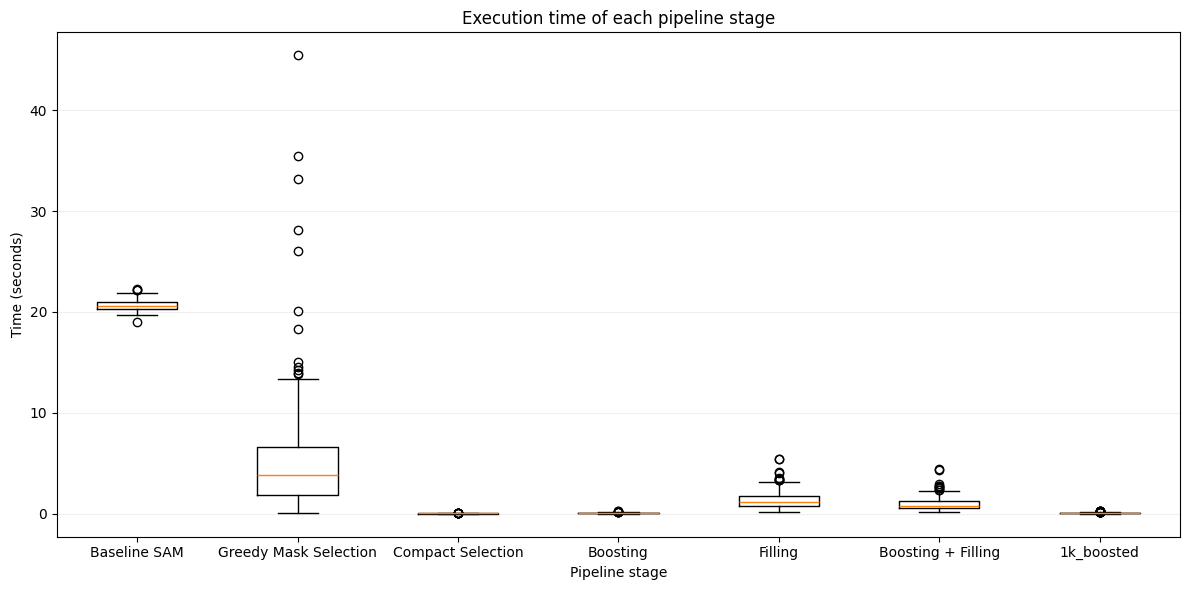

In [8]:
times = {
    "Baseline SAM": df.loc[
        df["config"] == "base_SAM", "time_sam"
    ].dropna(),

    "Greedy Mask Selection": df.loc[
        df["config"] == "base_SAM", "time_coverage"
    ].dropna(),

    "Compact Selection": df.loc[
        df["config"] == "base_SAM", "time_compact"
    ].dropna(),

    "Boosting": df.loc[
        df["config"] == "boosted", "time_boost"
    ].dropna(),

    "Filling": df.loc[
        df["config"] == "filled", "time_fill"
    ].dropna(),

    "Boosting + Filling": df.loc[
        df["config"] == "boosted_filled", "time_fill"
    ].dropna(),

    "1k_boosted": df.loc[
        df["config"] == "1k_boosted", "time_boost"
    ].dropna(),
}

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    list(times.values()),
    tick_labels=list(times.keys()),
    showfliers=True
)

ax.set_title("Execution time of each pipeline stage")
ax.set_xlabel("Pipeline stage")
ax.set_ylabel("Time (seconds)")
ax.grid(axis="y", alpha=0.20)

plt.tight_layout()
plt.show()

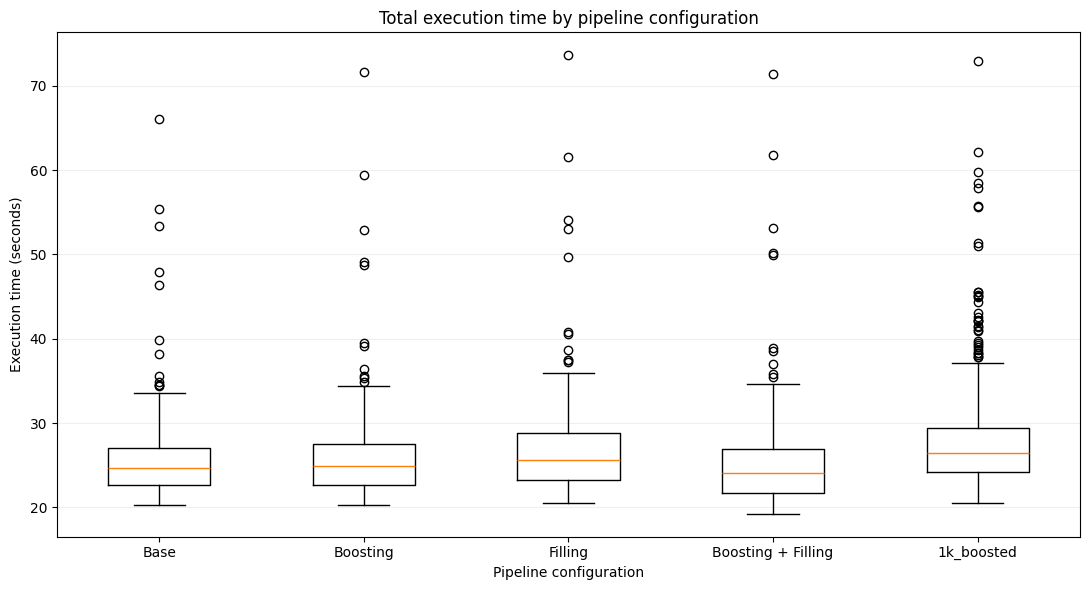

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Copia del dataframe per evitare modifiche accidentali
df_time = df.copy()

# ------------------------------------------------------------
# Tempo delle fasi comuni
# ------------------------------------------------------------

common_time = (
    df_time["time_sam"].fillna(0)
    + df_time["time_coverage"].fillna(0)
    + df_time["time_compact"].fillna(0)
)

# ------------------------------------------------------------
# Tempo totale ricostruito per ciascuna configurazione
# ------------------------------------------------------------

df_time["pipeline_time"] = common_time

# Boosting + 1k_boosted
mask = df_time["config"].isin(["boosted", "1k_boosted"])
df_time.loc[mask, "pipeline_time"] += (
    df_time.loc[mask, "time_boost"].fillna(0)
)

# Filling
mask = df_time["config"] == "filled"
df_time.loc[mask, "pipeline_time"] += (
    df_time.loc[mask, "time_fill"].fillna(0)
)

# Boosting + Filling
mask = df_time["config"] == "boosted_filled"
df_time.loc[mask, "pipeline_time"] += (
    df_time.loc[mask, "time_boost"].fillna(0)
    + df_time.loc[mask, "time_fill"].fillna(0)
)

# ------------------------------------------------------------
# Dati per il boxplot
# ------------------------------------------------------------

pipeline_times = {
    "Base": df_time.loc[
        df_time["config"] == "base_SAM", "pipeline_time"
    ].dropna(),

    "Boosting": df_time.loc[
        df_time["config"] == "boosted", "pipeline_time"
    ].dropna(),

    "Filling": df_time.loc[
        df_time["config"] == "filled", "pipeline_time"
    ].dropna(),

    "Boosting + Filling": df_time.loc[
        df_time["config"] == "boosted_filled", "pipeline_time"
    ].dropna(),

    "1k_boosted": df_time.loc[
        df_time["config"] == "1k_boosted", "pipeline_time"
    ].dropna(),
}

# ------------------------------------------------------------
# Boxplot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.boxplot(
    list(pipeline_times.values()),
    tick_labels=list(pipeline_times.keys()),
    showfliers=True
)

ax.set_title("Total execution time by pipeline configuration")
ax.set_xlabel("Pipeline configuration")
ax.set_ylabel("Execution time (seconds)")
ax.grid(axis="y", alpha=0.20)

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

config_names = {
    "base_SAM": "Base",
    "boosted": "Boosting",
    "filled": "Filling",
    "boosted_filled": "Boosting + Filling",
    "1k_boosted": "1k_boosted"
}

summary_time = (
    df[df["config"].isin(config_names.keys())]
    .groupby("config")["total_time_sec"]
    .agg(
        N="count",
        Total="sum",
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
    .rename(index=config_names)
    .reindex([
        "Base",
        "Boosting",
        "Filling",
        "Boosting + Filling",
        "1k_boosted"
    ])
)

print(summary_time.round(2))

                       N     Total   Mean    Std  Median    Min    Max
config                                                                
Base                 300  15428.56  51.43  15.51   61.19  22.21  71.58
Boosting             300  15462.83  51.54  15.32   61.02  22.08  71.65
Filling              300  15763.02  52.54  15.28   61.91  22.21  73.71
Boosting + Filling   300  14752.50  49.18  14.10   57.63  21.05  71.39
1k_boosted          1000  55552.79  55.55  16.27   62.83  20.75  80.46


## STEPS

In [11]:
steps_summary = (
    df.groupby("config")["steps"]
    .agg(
        N="count",
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
)

print("=== Number of steps by configuration ===")
print("Descriptive statistics of the number of processing steps for each configuration.\n")

print(steps_summary.round(2))

=== Number of steps by configuration ===
Descriptive statistics of the number of processing steps for each configuration.

                   N  Mean   Std  Median  Min  Max
config                                            
1k_boosted      1000  2.30  0.84     3.0    1    3
base_SAM         300  2.24  0.85     3.0    1    3
boosted          300  2.24  0.85     3.0    1    3
boosted_filled   300  2.24  0.85     3.0    1    3
filled           300  2.24  0.85     3.0    1    3


In [12]:
steps_distribution = pd.crosstab(
    df["config"],
    df["steps"]
)

print("=== Distribution of steps by configuration ===")
print("Number of images associated with each number of processing steps.\n")

print(steps_distribution)

=== Distribution of steps by configuration ===
Number of images associated with each number of processing steps.

steps             1    2    3
config                       
1k_boosted      245  210  545
base_SAM         80   67  153
boosted          80   67  153
boosted_filled   80   67  153
filled           80   67  153


## PARAMS HISTORY

In [13]:
import re
import numpy as np
import pandas as pd


def extract_sam_times(params_history):
    """
    Estrae i tempi SAM dei singoli step da params_history.
    Restituisce una lista di tempi in secondi.
    """
    if params_history is None:
        return []

    # Gestione eventuali NaN
    if isinstance(params_history, float) and np.isnan(params_history):
        return []

    times = []

    for entry in params_history:
        match = re.search(r"sec=([0-9.]+)", entry)

        if match:
            times.append(float(match.group(1)))

    return times


# Tempi dei singoli step
df["sam_step_times"] = df["params_history"].apply(
    extract_sam_times
)

# Tempo SAM cumulativo
df["time_sam_total"] = df["sam_step_times"].apply(
    lambda x: sum(x) if len(x) > 0 else np.nan
)

# Controllo: numero di tempi estratti
df["n_sam_steps_extracted"] = df["sam_step_times"].apply(len)


print("=== SAM step times extraction ===")
print("SAM execution times extracted from params_history for each configuration.\n")

=== SAM step times extraction ===
SAM execution times extracted from params_history for each configuration.



In [14]:
check = df[
    ["image_id", "config", "steps", "n_sam_steps_extracted"]
].copy()

check["match"] = (
    check["steps"] == check["n_sam_steps_extracted"]
)

print("=== SAM steps consistency check ===")
print("Checks whether the declared number of steps matches the number of SAM times extracted.\n")

print(check["match"].value_counts())

=== SAM steps consistency check ===
Checks whether the declared number of steps matches the number of SAM times extracted.

match
True    2200
Name: count, dtype: int64


In [15]:
sam_total_summary = (
    df.groupby("config")["time_sam_total"]
    .agg(
        N="count",
        Total="sum",
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
)

print("=== Total SAM execution time by configuration ===")
print("Descriptive statistics of the cumulative SAM time across all steps.\n")

print(sam_total_summary.round(2))

=== Total SAM execution time by configuration ===
Descriptive statistics of the cumulative SAM time across all steps.

                   N     Total   Mean    Std  Median    Min    Max
config                                                            
1k_boosted      1000  49823.88  49.82  18.84   60.76  18.89  74.61
base_SAM         300  13901.18  46.34  17.93   60.10  19.01  66.77
boosted          300  13836.97  46.12  17.84   59.94  19.14  66.19
boosted_filled   300  12945.21  43.15  16.68   56.15  18.40  61.68
filled           300  13888.48  46.29  17.94   60.02  19.07  66.22


In [16]:
sam_by_steps = (
    df.groupby("steps")["time_sam_total"]
    .agg(
        N="count",
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
)

print("=== SAM execution time by number of steps ===")
print("Descriptive statistics of cumulative SAM time grouped by the number of steps.\n")

print(sam_by_steps.round(2))

=== SAM execution time by number of steps ===
Descriptive statistics of cumulative SAM time grouped by the number of steps.

          N   Mean   Std  Median    Min    Max
steps                                         
1       565  20.41  1.19   20.14  18.40  24.14
2       478  41.37  2.48   40.79  37.11  49.69
3      1157  63.17  3.88   62.20  55.40  74.61


In [17]:
sam_base = df[df["config"] == "base_SAM"]

sam_by_steps_base = (
    sam_base.groupby("steps")["time_sam_total"]
    .agg(
        N="count",
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
)

print("=== SAM execution time by number of steps — Base SAM ===")
print("Cumulative SAM execution time grouped by number of steps for the Base configuration.\n")

print(sam_by_steps_base.round(2))

=== SAM execution time by number of steps — Base SAM ===
Cumulative SAM execution time grouped by number of steps for the Base configuration.

         N   Mean   Std  Median    Min    Max
steps                                        
1       80  20.19  0.35   20.16  19.01  21.39
2       67  41.00  0.78   40.81  39.62  43.97
3      153  62.35  1.29   62.23  57.51  66.77


80 immagini terminano dopo 1 step;
- 67 dopo 2 step;
- 153 dopo 3 step;
  
sul solo esperimento Base, il tempo SAM cumulativo medio è:
- 1 step: 20,19 s
- 2 step: 41,00 s
- 3 step: 62,35 s
  
sull'intero insieme delle quattro configurazioni:
- 1 step: 19,82 s medi
- 2 step: 40,22 s medi
- 3 step: 61,19 s medi
  
la ricostruzione da params_history è valida su tutte le 1200 esecuzioni.

In [18]:
stage_summary = pd.DataFrame({
    "SAM": df.loc[
        df["config"] == "base_SAM", "time_sam_total"
    ].describe(),

    "Greedy Selection": df.loc[
        df["config"] == "base_SAM", "time_coverage"
    ].describe(),

    "Compact Selection": df.loc[
        df["config"] == "base_SAM", "time_compact"
    ].describe(),

    "Boosting": df.loc[
        df["config"] == "boosted", "time_boost"
    ].describe(),

    "Filling": df.loc[
        df["config"] == "filled", "time_fill"
    ].describe(),

    "Filling after Boosting": df.loc[
        df["config"] == "boosted_filled", "time_fill"
    ].describe(),

    "1k_boosted": df.loc[
        df["config"] == "1k_boosted", "time_boost"
    ].describe(),
}).T

stage_summary = stage_summary[
    ["count", "mean", "std", "50%", "min", "max"]
]

stage_summary.columns = [
    "N", "Mean", "Std", "Median", "Min", "Max"
]

print("=== Execution time by pipeline stage ===")
print("Descriptive statistics of the execution time of each pipeline stage.\n")

print(stage_summary.round(3))

=== Execution time by pipeline stage ===
Descriptive statistics of the execution time of each pipeline stage.

                             N    Mean     Std  Median     Min     Max
SAM                      300.0  46.337  17.932  60.095  19.010  66.770
Greedy Selection         300.0   5.047   5.154   3.864   0.093  45.448
Compact Selection        300.0   0.028   0.018   0.024   0.003   0.098
Boosting                 300.0   0.064   0.038   0.055   0.007   0.227
Filling                  300.0   1.320   0.844   1.110   0.126   5.409
Filling after Boosting   300.0   0.932   0.616   0.785   0.118   4.436
1k_boosted              1000.0   0.069   0.040   0.061   0.006   0.247


## WITH STEPS TIME

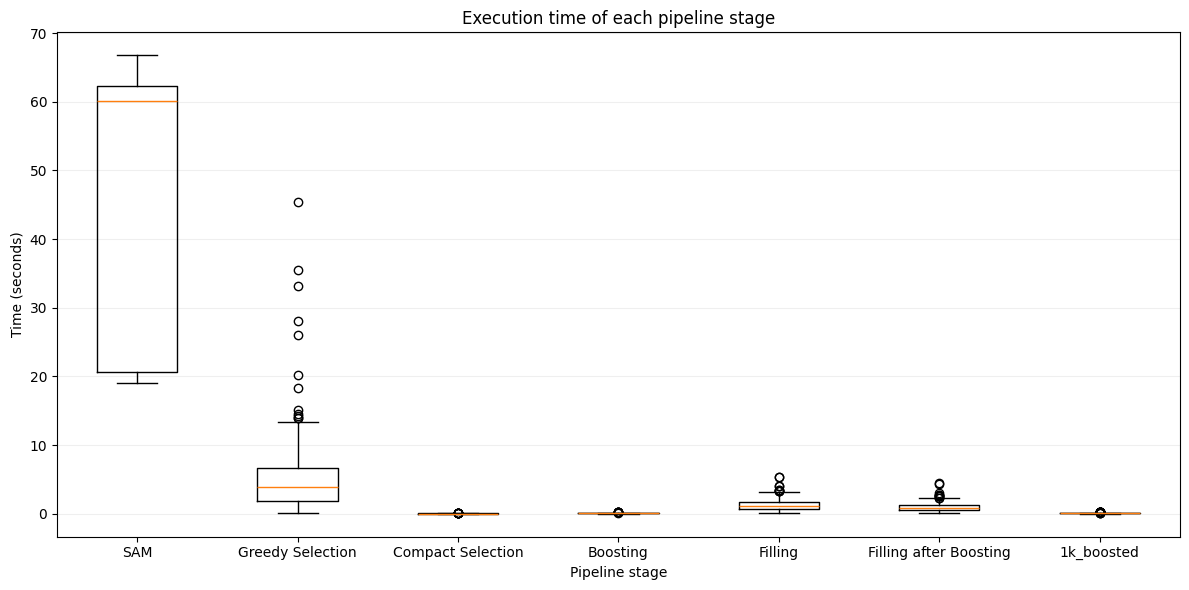

In [19]:
times = {
    "SAM": df.loc[
        df["config"] == "base_SAM", "time_sam_total"
    ].dropna(),

    "Greedy Selection": df.loc[
        df["config"] == "base_SAM", "time_coverage"
    ].dropna(),

    "Compact Selection": df.loc[
        df["config"] == "base_SAM", "time_compact"
    ].dropna(),

    "Boosting": df.loc[
        df["config"] == "boosted", "time_boost"
    ].dropna(),

    "Filling": df.loc[
        df["config"] == "filled", "time_fill"
    ].dropna(),

    "Filling after Boosting": df.loc[
        df["config"] == "boosted_filled", "time_fill"
    ].dropna(),

    "1k_boosted": df.loc[
        df["config"] == "1k_boosted", "time_boost"
    ].dropna(),
}

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    list(times.values()),
    tick_labels=list(times.keys()),
    showfliers=True
)

ax.set_title("Execution time of each pipeline stage")
ax.set_xlabel("Pipeline stage")
ax.set_ylabel("Time (seconds)")
ax.grid(axis="y", alpha=0.20)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/steps_pipelines.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

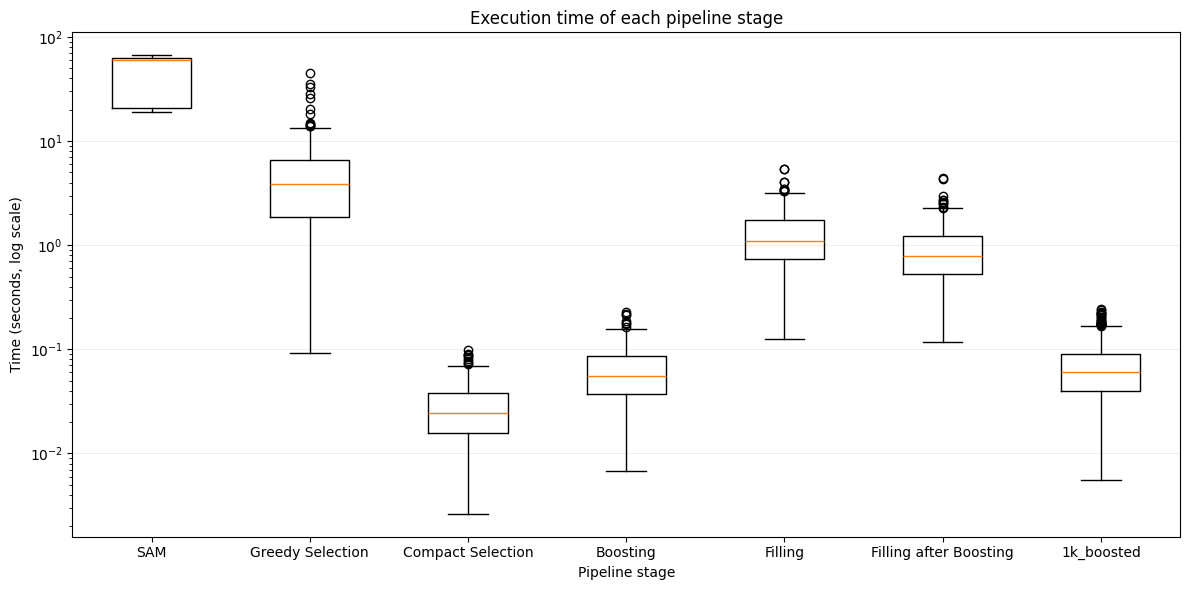

In [20]:
times = {
    "SAM": df.loc[
        df["config"] == "base_SAM", "time_sam_total"
    ].dropna(),

    "Greedy Selection": df.loc[
        df["config"] == "base_SAM", "time_coverage"
    ].dropna(),

    "Compact Selection": df.loc[
        df["config"] == "base_SAM", "time_compact"
    ].dropna(),

    "Boosting": df.loc[
        df["config"] == "boosted", "time_boost"
    ].dropna(),

    "Filling": df.loc[
        df["config"] == "filled", "time_fill"
    ].dropna(),

    "Filling after Boosting": df.loc[
        df["config"] == "boosted_filled", "time_fill"
    ].dropna(),

    "1k_boosted": df.loc[
        df["config"] == "1k_boosted", "time_boost"
    ].dropna(),
}

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    list(times.values()),
    tick_labels=list(times.keys()),
    showfliers=True
)

ax.set_yscale("log")

ax.set_title("Execution time of each pipeline stage")
ax.set_xlabel("Pipeline stage")
ax.set_ylabel("Time (seconds, log scale)")

ax.grid(axis="y", alpha=0.20)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/steps_pipelines.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

## CONFIGURATION TIMES

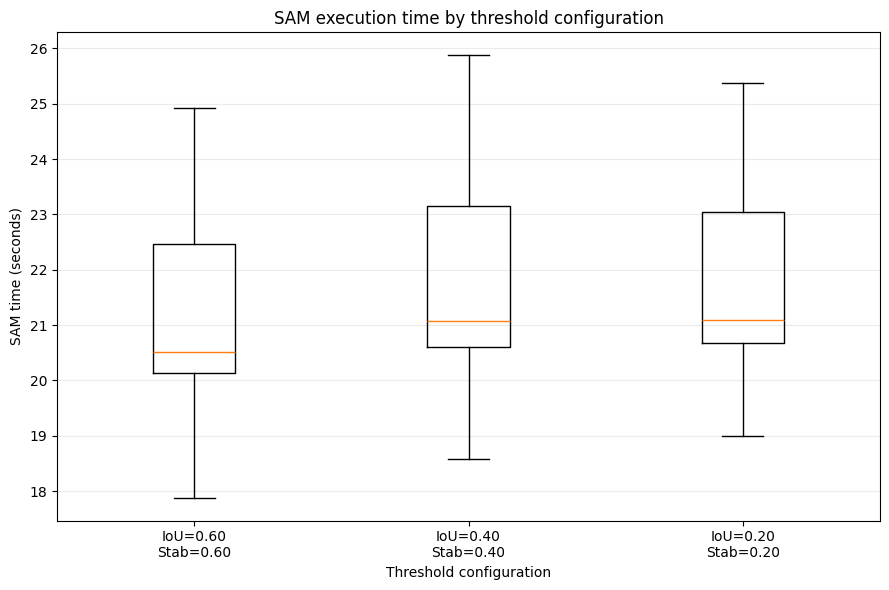

In [21]:
import re

sam_df = df[
    df["config"].isin(["base_SAM", "1k_boosted"])
]

times = {}

for history in sam_df["params_history"]:

    for item in history:

        match = re.search(
            r"iou=([\d.]+)-stab=([\d.]+)-masks=\d+-sec=([\d.]+)",
            item
        )

        if match:
            iou = float(match.group(1))
            stab = float(match.group(2))
            sec = float(match.group(3))

            config = f"IoU={iou:.2f}\nStab={stab:.2f}"

            times.setdefault(config, []).append(sec)


plt.figure(figsize=(9, 6))

plt.boxplot(
    times.values(),
    tick_labels=times.keys(),
    showfliers=True
)

plt.title("SAM execution time by threshold configuration")
plt.xlabel("Threshold configuration")
plt.ylabel("SAM time (seconds)")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/time_thresholds.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

## PERCENT

In [22]:
import re
import numpy as np

def extract_sam_times(params_history):
    if params_history is None:
        return []

    if isinstance(params_history, float) and np.isnan(params_history):
        return []

    times = []

    for entry in params_history:
        match = re.search(r"sec=([0-9.]+)", entry)

        if match:
            times.append(float(match.group(1)))

    return times


df["sam_step_times"] = df["params_history"].apply(
    extract_sam_times
)

df["time_sam_total"] = df["sam_step_times"].apply(
    lambda x: sum(x) if len(x) > 0 else np.nan
)

In [23]:
base = df[df["config"] == "base_SAM"]

# Tempi medi della pipeline Base
sam = base["time_sam_total"].mean()
greedy = base["time_coverage"].mean()
compact = base["time_compact"].mean()

base_total = sam + greedy + compact

# Tempi medi del post-processing
boost = df.loc[
    df["config"] == "boosted",
    "time_boost"
].mean()

boost_1k = df.loc[
    df["config"] == "1k_boosted",
    "time_boost"
].mean()

fill = df.loc[
    df["config"] == "filled",
    "time_fill"
].mean()

boost_fill = (
    df.loc[
        df["config"] == "boosted_filled",
        "time_boost"
    ].mean()
    +
    df.loc[
        df["config"] == "boosted_filled",
        "time_fill"
    ].mean()
)

# Pipeline Base
print("PIPELINE BASE")
print(f"SAM:     {sam:.3f} s ({sam / base_total * 100:.2f}%)")
print(f"Greedy:  {greedy:.3f} s ({greedy / base_total * 100:.2f}%)")
print(f"Compact: {compact:.3f} s ({compact / base_total * 100:.2f}%)")
print(f"Totale:  {base_total:.3f} s")

# Overhead rispetto alla Base
print("\nOVERHEAD POST-PROCESSING")
print(
    f"Boosting:           {boost:.3f} s "
    f"({boost / base_total * 100:.2f}%)"
)
print(
    f"1k_boosted:         {boost_1k:.3f} s "
    f"({boost_1k / base_total * 100:.2f}%)"
)
print(
    f"Filling:            {fill:.3f} s "
    f"({fill / base_total * 100:.2f}%)"
)
print(
    f"Boosting + Filling: {boost_fill:.3f} s "
    f"({boost_fill / base_total * 100:.2f}%)"
)

PIPELINE BASE
SAM:     46.337 s (90.13%)
Greedy:  5.047 s (9.82%)
Compact: 0.028 s (0.05%)
Totale:  51.412 s

OVERHEAD POST-PROCESSING
Boosting:           0.064 s (0.12%)
1k_boosted:         0.069 s (0.13%)
Filling:            1.320 s (2.57%)
Boosting + Filling: 0.993 s (1.93%)


In [24]:
print("MEAN")
print(
    "Boosting:",
    df.loc[df["config"] == "boosted", "time_boost"].mean()
)

print(
    "1k_boosted:",
    df.loc[df["config"] == "1k_boosted", "time_boost"].mean()
)

print(
    "Filling:",
    df.loc[df["config"] == "filled", "time_fill"].mean()
)

print(
    "Filling dopo Boosting:",
    df.loc[df["config"] == "boosted_filled", "time_fill"].mean()
)

MEAN
Boosting: 0.0635657779375712
1k_boosted: 0.06879438781738281
Filling: 1.3196011662483216
Filling dopo Boosting: 0.931646941502889


## COVERAGE

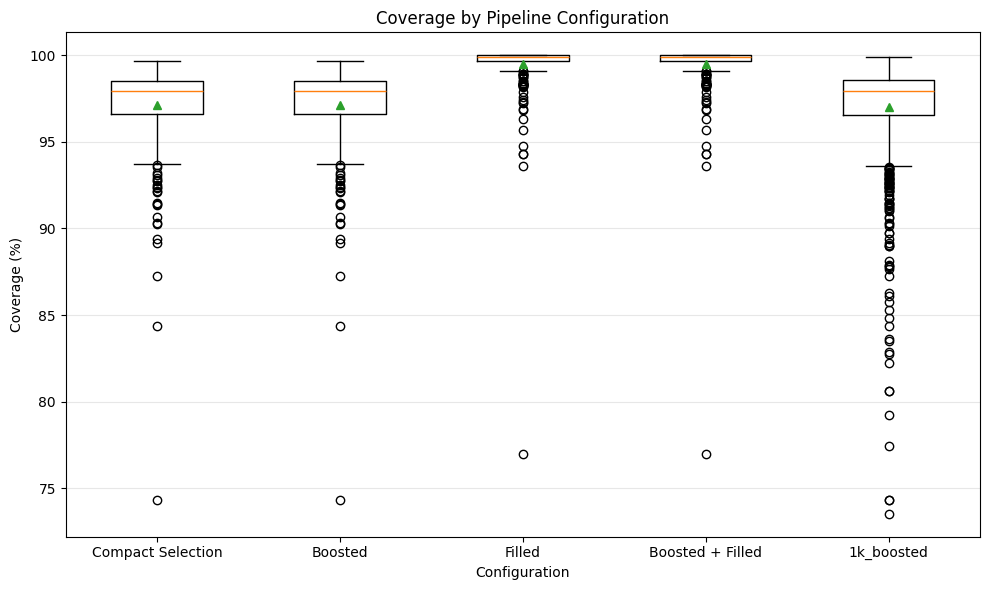

In [25]:
import json

coverage_data = {}

for config, folder in EXPERIMENTS.items():
    coverages = []

    for json_path in sorted(folder.glob("*_results.json")):
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        coverage = data.get("coverage")

        if coverage is not None:
            coverages.append(float(coverage))

    coverage_data[config] = coverages


plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        coverage_data["base_SAM"],
        coverage_data["boosted"],
        coverage_data["filled"],
        coverage_data["boosted_filled"],
        coverage_data["1k_boosted"],
    ],
    tick_labels=[
        "Compact Selection",
        "Boosted",
        "Filled",
        "Boosted + Filled",
        "1k_boosted"
    ],
    showmeans=True
)

plt.title("Coverage by Pipeline Configuration")
plt.xlabel("Configuration")
plt.ylabel("Coverage (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/coverage_pipeline_configuration.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [26]:
coverage_summary = (
    df.groupby("config")["coverage"]
      .agg(["count", "mean", "std", "median", "min", "max"])
)

print(coverage_summary.round(4))

                count     mean     std   median      min       max
config                                                            
1k_boosted       1000  96.9972  2.9599  97.9192  73.5345   99.8976
base_SAM          300  97.1295  2.5219  97.9113  74.3474   99.6699
boosted           300  97.1295  2.5219  97.9113  74.3474   99.6699
boosted_filled    300  99.5120  1.5790  99.9232  76.9517  100.0000
filled            300  99.5120  1.5790  99.9232  76.9517  100.0000


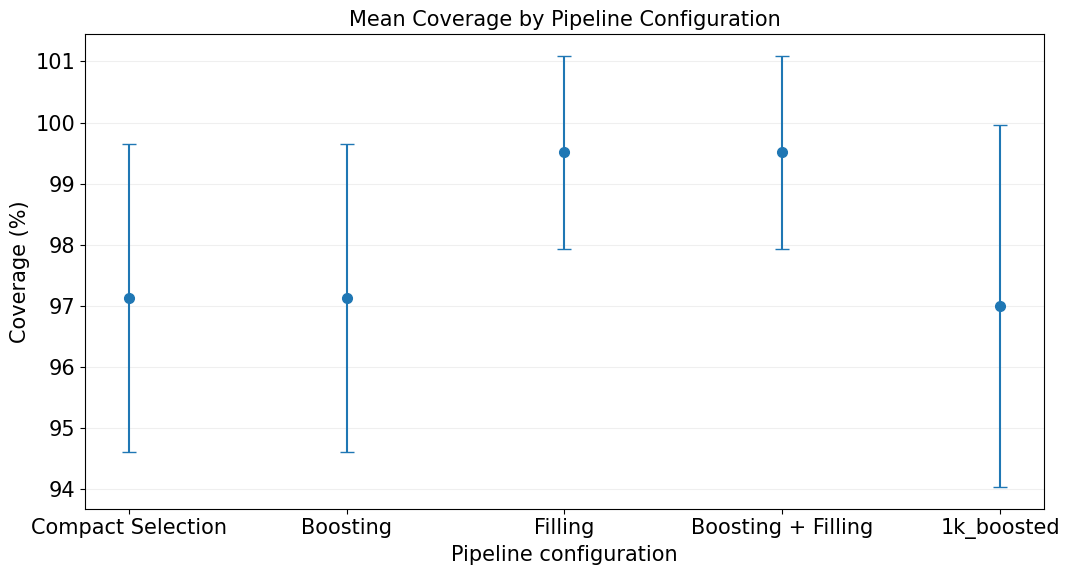

In [27]:
import matplotlib.pyplot as plt
import numpy as np

FONT_SIZE = 15

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

config_order = [
    "base_SAM",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted"
]

config_labels = [
    "Compact Selection",
    "Boosting",
    "Filling",
    "Boosting + Filling",
    "1k_boosted"
]

# Media e deviazione standard della coverage
coverage_stats = (
    df[df["config"].isin(config_order)]
    .groupby("config")["coverage"]
    .agg(["mean", "std"])
    .reindex(config_order)
)

means = coverage_stats["mean"].to_numpy()
stds = coverage_stats["std"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(config_labels))

ax.errorbar(
    x,
    means,
    yerr=stds,
    fmt="o",
    capsize=5,
    markersize=7
)

ax.set_xticks(x)
ax.set_xticklabels(config_labels)

ax.set_xlabel("Pipeline configuration")
ax.set_ylabel("Coverage (%)")
ax.set_title("Mean Coverage by Pipeline Configuration")

ax.grid(axis="y", alpha=0.20)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/coverage_means.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### outlier

In [28]:
print("=== Coverage outlier analysis by configuration ===")
print("Outliers identified using the 1.5 × IQR rule.")

for config in df["config"].unique():
    x = df.loc[df["config"] == config, "coverage"].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = x[(x < lower) | (x > upper)]

    print(f"\n{config}")
    print(f"Q1: {q1:.4f}")
    print(f"Q3: {q3:.4f}")
    print(f"IQR: {iqr:.4f}")
    print(f"Lower bound: {lower:.4f}")
    print(f"Upper bound: {upper:.4f}")
    print(f"Numero outlier: {len(outliers)}")

=== Coverage outlier analysis by configuration ===
Outliers identified using the 1.5 × IQR rule.

base_SAM
Q1: 96.5821
Q3: 98.5362
IQR: 1.9541
Lower bound: 93.6509
Upper bound: 101.4674
Numero outlier: 23

filled
Q1: 99.6399
Q3: 99.9906
IQR: 0.3507
Lower bound: 99.1138
Upper bound: 100.5166
Numero outlier: 38

boosted
Q1: 96.5821
Q3: 98.5362
IQR: 1.9541
Lower bound: 93.6509
Upper bound: 101.4674
Numero outlier: 23

boosted_filled
Q1: 99.6399
Q3: 99.9906
IQR: 0.3507
Lower bound: 99.1138
Upper bound: 100.5166
Numero outlier: 38

1k_boosted
Q1: 96.5710
Q3: 98.5809
IQR: 2.0099
Lower bound: 93.5562
Upper bound: 101.5957
Numero outlier: 85


### with filling

In [29]:
coverage_pivot = df.pivot(
    index="image_id",
    columns="config",
    values="coverage"
)

coverage_pivot["gain_filling"] = (
    coverage_pivot["filled"] -
    coverage_pivot["base_SAM"]
)

coverage_pivot["gain_boosted_filling"] = (
    coverage_pivot["boosted_filled"] -
    coverage_pivot["boosted"]
)

print("=== Coverage gain produced by Filling ===")
print("Comparison of coverage before and after applying the Filling operation.")

for col in ["gain_filling", "gain_boosted_filling"]:
    x = coverage_pivot[col].dropna()

    print(f"\n{col}")
    print(f"N: {len(x)}")
    print(f"Mean gain: {x.mean():.6f}")
    print(f"Median gain: {x.median():.6f}")
    print(f"Min gain: {x.min():.6f}")
    print(f"Max gain: {x.max():.6f}")
    print(f"Images improved: {(x > 0).sum()}")
    print(f"Images unchanged: {(x == 0).sum()}")
    print(f"Images worsened: {(x < 0).sum()}")

=== Coverage gain produced by Filling ===
Comparison of coverage before and after applying the Filling operation.

gain_filling
N: 300
Mean gain: 2.382431
Median gain: 1.985032
Min gain: 0.330064
Max gain: 11.330336
Images improved: 300
Images unchanged: 0
Images worsened: 0

gain_boosted_filling
N: 300
Mean gain: 2.382431
Median gain: 1.985032
Min gain: 0.330064
Max gain: 11.330336
Images improved: 300
Images unchanged: 0
Images worsened: 0


## Sum total time vs total masks obtained

In [30]:
import json

time_masks_data = {}

for config, folder in EXPERIMENTS.items():

    total_time = 0
    total_masks = 0

    for json_path in sorted(folder.glob("*_results.json")):
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Tempo totale dell'immagine
        total_time += float(data["total_time_sec"])

        # Numero di maschere finali della configurazione
        if config == "base_SAM":
            n_masks = data["n_compact_instances"]

        elif config in ["boosted", "1k_boosted"]:
            n_masks = data["n_refined_instances"]

        elif config in ["filled", "boosted_filled"]:
            n_masks = data["n_unique_filler"]

        else:
            n_masks = None

        if n_masks is not None:
            total_masks += int(n_masks)

    time_masks_data[config] = {
        "total_time": total_time,
        "total_masks": total_masks
    }

In [31]:
print("=== Total masks and execution time by configuration ===")
print("Total number of final masks and cumulative execution time for each configuration.\n")

for config, values in time_masks_data.items():
    print(
        f"{config:16s} | "
        f"Total masks: {values['total_masks']:6d} | "
        f"Total time: {values['total_time']:.2f} s"
    )

=== Total masks and execution time by configuration ===
Total number of final masks and cumulative execution time for each configuration.

base_SAM         | Total masks:  32626 | Total time: 15428.56 s
filled           | Total masks:  32605 | Total time: 15763.02 s
boosted          | Total masks:  22992 | Total time: 15462.83 s
boosted_filled   | Total masks:  22971 | Total time: 14752.50 s
1k_boosted       | Total masks:  74284 | Total time: 55552.79 s


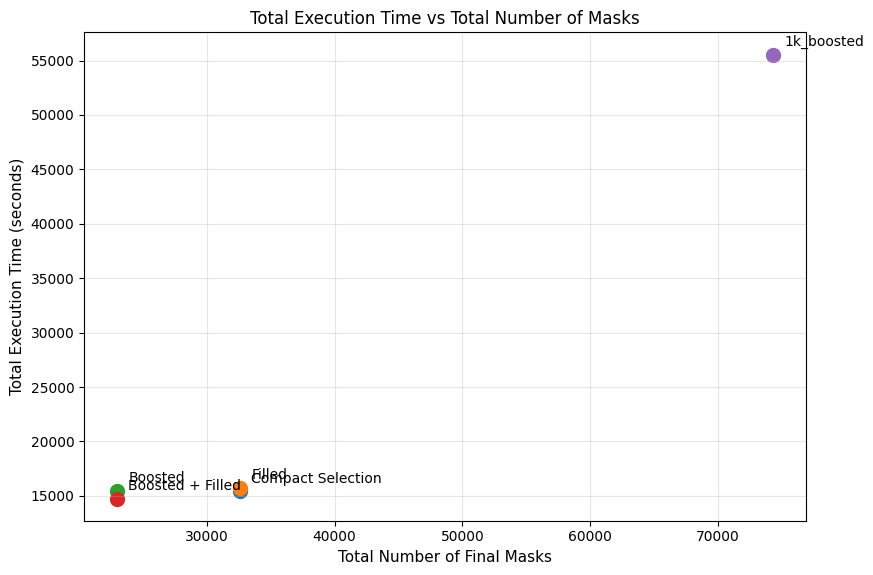

In [32]:
plt.figure(figsize=(9, 6))

labels = {
    "base_SAM": "Compact Selection",
    "boosted": "Boosted",
    "filled": "Filled",
    "boosted_filled": "Boosted + Filled",
    "1k_boosted": "1k_boosted"
}

for config, values in time_masks_data.items():

    plt.scatter(
        values["total_masks"],
        values["total_time"],
        s=100
    )

    plt.annotate(
        labels[config],
        (
            values["total_masks"],
            values["total_time"]
        ),
        xytext=(8, 6),
        textcoords="offset points",
        fontsize=10
    )

plt.title(
    "Total Execution Time vs Total Number of Masks",
    fontsize=12
)

plt.xlabel(
    "Total Number of Final Masks",
    fontsize=11
)

plt.ylabel(
    "Total Execution Time (seconds)",
    fontsize=11
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/time_vs_masks.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

## Number of masks vs time

In [33]:
import json

masks_time_data = {}

for config, folder in EXPERIMENTS.items():

    n_masks_list = []
    time_list = []

    for json_path in sorted(folder.glob("*_results.json")):

        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Numero di maschere finali
        if config == "base_SAM":
            n_masks = data.get("n_compact_instances")

        elif config in ["boosted", "1k_boosted"]:
            n_masks = data.get("n_refined_instances")

        elif config in ["filled", "boosted_filled"]:
            n_masks = data.get("n_unique_filler")

        else:
            n_masks = None

        total_time = data.get("total_time_sec")

        if n_masks is not None and total_time is not None:
            n_masks_list.append(int(n_masks))
            time_list.append(float(total_time))

    masks_time_data[config] = {
        "n_masks": n_masks_list,
        "time": time_list
    }

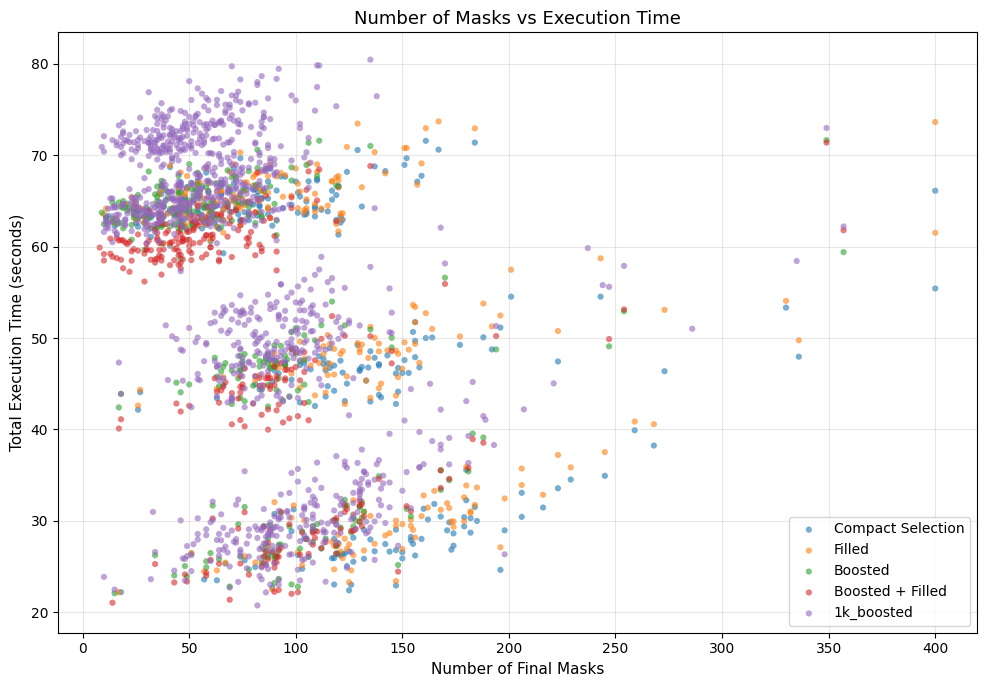

In [34]:
plt.figure(figsize=(10, 7))

FONT_SIZE = 11

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 13,
})

labels = {
    "base_SAM": "Compact Selection",
    "boosted": "Boosted",
    "filled": "Filled",
    "boosted_filled": "Boosted + Filled",
    "1k_boosted": "1k_boosted"
}

for config, values in masks_time_data.items():

    plt.scatter(
        values["n_masks"],
        values["time"],
        s=20,
        alpha=0.6,
        edgecolors="none",
        label=labels[config]
    )

plt.title("Number of Masks vs Execution Time")
plt.xlabel("Number of Final Masks")
plt.ylabel("Total Execution Time (seconds)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/n_masks_vs_time.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [35]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd

configs = {
    "Base": ("base_SAM", "n_compact_instances"),
    "Boosting": ("boosted", "n_boosted_instances"),
    "Filling": ("filled", "n_filled_instances"),
    "Boosting + Filling": ("boosted_filled", "n_filled_instances"),
    "1k_boosted": ("1k_boosted", "n_boosted_instances"),
}

results = []

for name, (config, mask_col) in configs.items():

    tmp = df[df["config"] == config][
        [mask_col, "total_time_sec"]
    ].dropna()

    pearson_r, pearson_p = pearsonr(
        tmp[mask_col],
        tmp["total_time_sec"]
    )

    spearman_rho, spearman_p = spearmanr(
        tmp[mask_col],
        tmp["total_time_sec"]
    )

    results.append({
        "Configuration": name,
        "N": len(tmp),
        "Pearson r": pearson_r,
        "Pearson p": pearson_p,
        "Spearman rho": spearman_rho,
        "Spearman p": spearman_p,
    })

corr_df = pd.DataFrame(results)

print("=== Correlation between number of masks and execution time ===")
print("Pearson and Spearman correlations for each pipeline configuration.\n")

print(corr_df.round(4).to_string(index=False))

=== Correlation between number of masks and execution time ===
Pearson and Spearman correlations for each pipeline configuration.

     Configuration    N  Pearson r  Pearson p  Spearman rho  Spearman p
              Base  300    -0.4104        0.0       -0.4136         0.0
          Boosting  300    -0.3857        0.0       -0.4435         0.0
           Filling  300    -0.3718        0.0       -0.3999         0.0
Boosting + Filling  300    -0.3458        0.0       -0.4201         0.0
        1k_boosted 1000    -0.4479        0.0       -0.4910         0.0


In [36]:
print("=== Correlation between number of masks and execution time ===")
print("Pearson and Spearman correlations for each pipeline configuration.\n")

for name, (config, mask_col) in configs.items():
    tmp = df[df["config"] == config][
        [mask_col, "total_time_sec"]
    ].dropna()

    pearson_r, pearson_p = pearsonr(
        tmp[mask_col],
        tmp["total_time_sec"]
    )

    spearman_rho, spearman_p = spearmanr(
        tmp[mask_col],
        tmp["total_time_sec"]
    )

    print(
        f"{name:20s} | "
        f"Pearson r={pearson_r:.4f}, p={pearson_p:.3e} | "
        f"Spearman rho={spearman_rho:.4f}, p={spearman_p:.3e}"
    )

=== Correlation between number of masks and execution time ===
Pearson and Spearman correlations for each pipeline configuration.

Base                 | Pearson r=-0.4104, p=1.286e-13 | Spearman rho=-0.4136, p=8.016e-14
Boosting             | Pearson r=-0.3857, p=4.468e-12 | Spearman rho=-0.4435, p=6.858e-16
Filling              | Pearson r=-0.3718, p=2.872e-11 | Spearman rho=-0.3999, p=6.012e-13
Boosting + Filling   | Pearson r=-0.3458, p=7.492e-10 | Spearman rho=-0.4201, p=2.935e-14
1k_boosted           | Pearson r=-0.4479, p=1.696e-50 | Spearman rho=-0.4910, p=8.451e-62


Pearson e Spearman sono due coefficienti di correlazione. Entrambi vanno da \(-1\) a \(+1\):

$$ -1 \leq r,\rho \leq 1 $$

- Un valore **positivo** indica che all'aumentare di una variabile tende ad aumentare anche l'altra;
- un valore **negativo** indica che all'aumentare di una tende a diminuire l'altra;
- un valore **vicino** a zero indica assenza o debolezza della relazione considerata.

La differenza è che **Pearson** (\(r\)) misura soprattutto una relazione lineare. In altre parole, verifica quanto bene i punti seguano approssimativamente una retta.

**Spearman** (\(\rho\)) considera invece l'ordine dei valori e misura una relazione monotona: verifica se, in generale, quando una variabile aumenta l'altra tende ad aumentare o diminuire, senza richiedere che la relazione segua una retta. È inoltre meno sensibile di Pearson ai valori estremi.

In [37]:
rows = []

for name, (config, mask_col) in configs.items():
    tmp = df[df["config"] == config].copy()

    for step in sorted(tmp["steps"].dropna().unique()):
        x = tmp[tmp["steps"] == step]

        rows.append({
            "Configuration": name,
            "Steps": int(step),
            "N": len(x),
            "Mean final masks": x[mask_col].mean(),
            "Mean total time": x["total_time_sec"].mean(),
        })

step_df = pd.DataFrame(rows)

print("=== Final masks and execution time by number of steps ===")
print("Mean number of final masks and total execution time grouped by configuration and number of steps.\n")

print(step_df.round(2).to_string(index=False))

=== Final masks and execution time by number of steps ===
Mean number of final masks and total execution time grouped by configuration and number of steps.

     Configuration  Steps   N  Mean final masks  Mean total time
              Base      1  80            156.55            29.73
              Base      2  67            128.97            46.79
              Base      3 153             74.91            64.81
          Boosting      1  80            115.20            30.24
          Boosting      2  67             87.31            47.03
          Boosting      3 153             51.80            64.66
           Filling      1  80            156.54            31.39
           Filling      2  67            128.97            48.17
           Filling      3 153             74.78            65.52
Boosting + Filling      1  80            115.19            29.89
Boosting + Filling      2  67             87.31            44.99
Boosting + Filling      3 153             51.67            61.0

**avere più maschere rende la pipeline più veloce.** Le immagini per cui SAM produce abbastanza maschere già con le soglie più restrittive terminano presto e tendono anche ad avere più regioni nella partizione finale. Al contrario, quando il numero di maschere non è sufficiente, SAM deve essere rieseguito con soglie progressivamente ridotte; il tempo aumenta perché vengono effettuate due o tre chiamate a SAM, mentre il numero finale di regioni risulta mediamente inferiore.

## Plot number of masks vs coverage


In [38]:
import json

masks_coverage_data = {}

for config, folder in EXPERIMENTS.items():

    n_masks_list = []
    coverage_list = []

    for json_path in sorted(folder.glob("*_results.json")):

        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Numero di maschere finali
        if config == "base_SAM":
            n_masks = data.get("n_compact_instances")

        elif config in ["boosted", "1k_boosted"]:
            n_masks = data.get("n_refined_instances")

        elif config in ["filled", "boosted_filled"]:
            n_masks = data.get("n_unique_filler")

        else:
            n_masks = None

        coverage = data.get("coverage")

        if n_masks is not None and coverage is not None:
            n_masks_list.append(int(n_masks))
            coverage_list.append(float(coverage))

    masks_coverage_data[config] = {
        "n_masks": n_masks_list,
        "coverage": coverage_list
    }

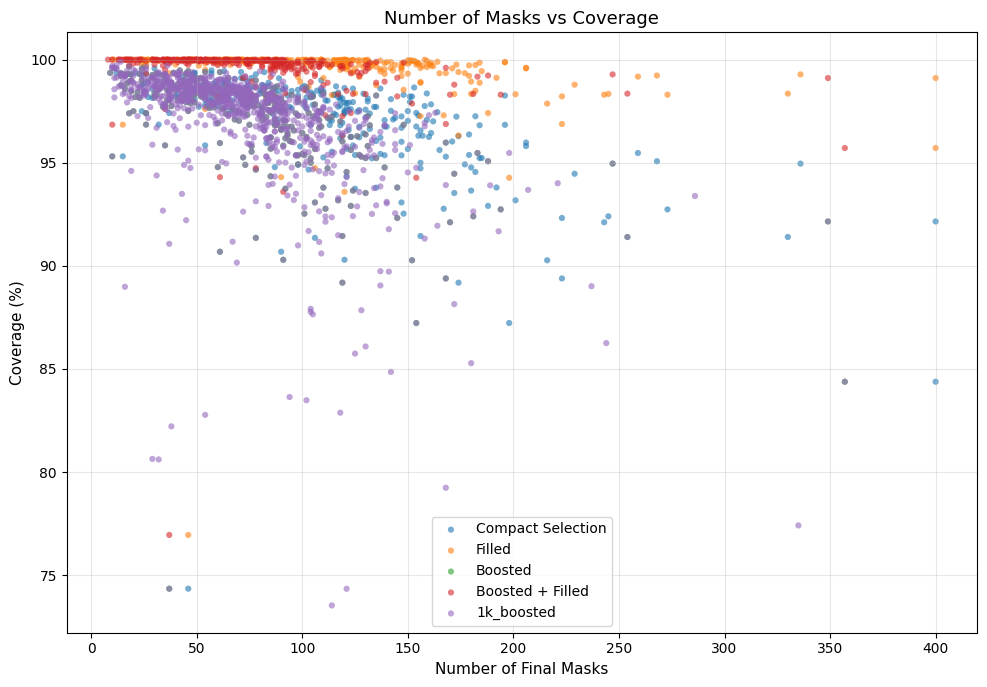

In [39]:
plt.figure(figsize=(10, 7))

labels = {
    "base_SAM": "Compact Selection",
    "boosted": "Boosted",
    "filled": "Filled",
    "boosted_filled": "Boosted + Filled",
    "1k_boosted": "1k_boosted"
}

for config, values in masks_coverage_data.items():

    plt.scatter(
        values["n_masks"],
        values["coverage"],
        s=20,
        alpha=0.6,
        edgecolors="none",
        label=labels[config]
    )

plt.title("Number of Masks vs Coverage", fontsize=13)
plt.xlabel("Number of Final Masks", fontsize=11)
plt.ylabel("Coverage (%)", fontsize=11)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/n_masks_vs_coverage.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [40]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd

configs = {
    "Base": ("base_SAM", "n_compact_instances"),
    "Boosting": ("boosted", "n_boosted_instances"),
    "Filling": ("filled", "n_filled_instances"),
    "Boosting + Filling": ("boosted_filled", "n_filled_instances"),
    "1k_boosted": ("1k_boosted", "n_boosted_instances"),
}

results = []

for name, (config, mask_col) in configs.items():
    tmp = df[df["config"] == config][
        [mask_col, "coverage"]
    ].dropna()

    pearson_r, pearson_p = pearsonr(
        tmp[mask_col],
        tmp["coverage"]
    )

    spearman_rho, spearman_p = spearmanr(
        tmp[mask_col],
        tmp["coverage"]
    )

    results.append({
        "Configuration": name,
        "N": len(tmp),
        "Pearson r": pearson_r,
        "Pearson p": pearson_p,
        "Spearman rho": spearman_rho,
        "Spearman p": spearman_p,
    })

corr_coverage_df = pd.DataFrame(results)

print("=== Correlation between number of masks and coverage ===")
print("Pearson and Spearman correlations for each pipeline configuration.\n")

for _, row in corr_coverage_df.iterrows():
    print(
        f"{row['Configuration']:20s} | "
        f"Pearson r={row['Pearson r']:.4f}, "
        f"p={row['Pearson p']:.3e} | "
        f"Spearman rho={row['Spearman rho']:.4f}, "
        f"p={row['Spearman p']:.3e}"
    )

=== Correlation between number of masks and coverage ===
Pearson and Spearman correlations for each pipeline configuration.

Base                 | Pearson r=-0.5585, p=5.282e-26 | Spearman rho=-0.7053, p=1.958e-46
Boosting             | Pearson r=-0.5801, p=2.232e-28 | Spearman rho=-0.7261, p=2.132e-50
Filling              | Pearson r=-0.1714, p=2.901e-03 | Spearman rho=-0.6453, p=1.008e-36
Boosting + Filling   | Pearson r=-0.1900, p=9.444e-04 | Spearman rho=-0.6673, p=5.083e-40
1k_boosted           | Pearson r=-0.5282, p=6.022e-73 | Spearman rho=-0.6909, p=8.932e-143


## Plot n masks (histogram)

In [41]:
print(CONFIG_ORDER)
print(masks_coverage_data.keys())

for config in CONFIG_ORDER:
    print(
        config,
        len(masks_coverage_data.get(config, {}).get("n_masks", []))
    )

['base_SAM', 'boosted', 'filled', 'boosted_filled', '1k_boosted']
dict_keys(['base_SAM', 'filled', 'boosted', 'boosted_filled', '1k_boosted'])
base_SAM 300
boosted 300
filled 300
boosted_filled 300
1k_boosted 1000


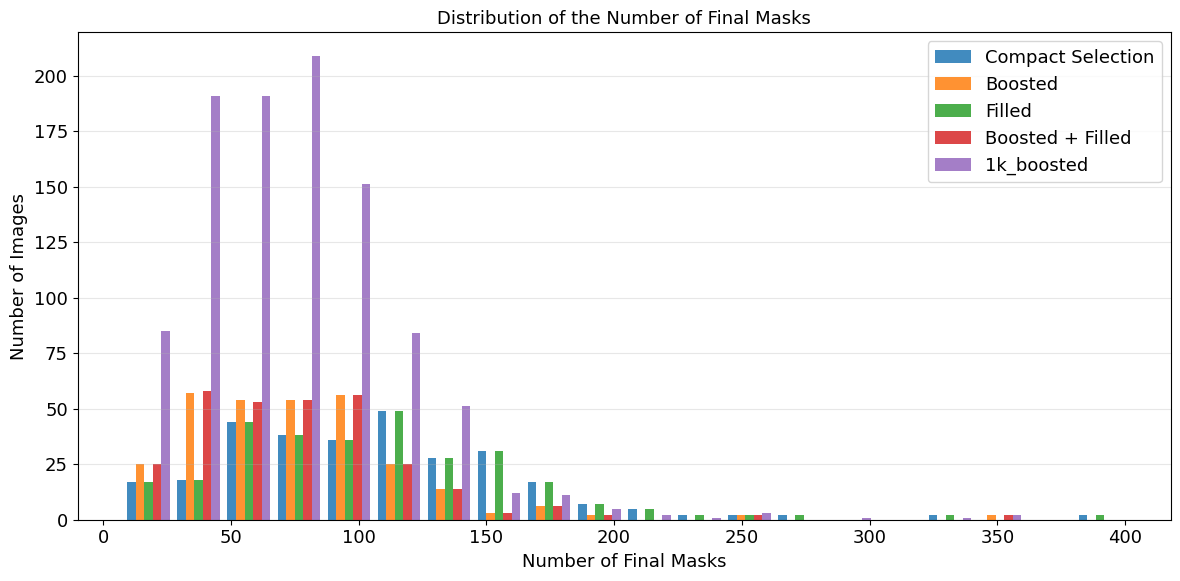

In [42]:
import numpy as np
import matplotlib.pyplot as plt

FONT_SIZE = 13

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

labels = {
    "base_SAM": "Compact Selection",
    "boosted": "Boosted",
    "filled": "Filled",
    "boosted_filled": "Boosted + Filled",
    "1k_boosted": "1k_boosted"
}

# Stessi intervalli per tutte le configurazioni
all_values = np.concatenate([
    np.asarray(masks_coverage_data[c]["n_masks"])
    for c in CONFIG_ORDER
])

bins = np.histogram_bin_edges(all_values, bins=20)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

# Larghezza di ogni barra
width = bin_width / len(CONFIG_ORDER) * 0.85

plt.figure(figsize=(12, 6))

for i, config in enumerate(CONFIG_ORDER):

    values = masks_coverage_data[config]["n_masks"]
    counts, _ = np.histogram(values, bins=bins)

    offset = (i - (len(CONFIG_ORDER) - 1) / 2) * width

    plt.bar(
        centers + offset,
        counts,
        width=width,
        label=labels[config],
        color=CONFIG_COLORS[config],
        alpha=0.85
    )

plt.title("Distribution of the Number of Final Masks")
plt.xlabel("Number of Final Masks")
plt.ylabel("Number of Images")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/distribution_n_masks.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [43]:
final_masks_df = pd.DataFrame({
    "Base": df.loc[
        df["config"] == "base_SAM",
        "n_compact_instances"
    ].reset_index(drop=True),

    "Boosting": df.loc[
        df["config"] == "boosted",
        "n_boosted_instances"
    ].reset_index(drop=True),

    "Filling": df.loc[
        df["config"] == "filled",
        "n_filled_instances"
    ].reset_index(drop=True),

    "Boosting + Filling": df.loc[
        df["config"] == "boosted_filled",
        "n_filled_instances"
    ].reset_index(drop=True),

    "1k_boosted": df.loc[
        df["config"] == "1k_boosted",
        "n_boosted_instances"
    ].reset_index(drop=True),
})

summary = final_masks_df.agg([
    "count",
    "mean",
    "std",
    "median",
    "min",
    "max"
]).T

print("=== Final number of masks by configuration ===")
print("Descriptive statistics of the number of final masks for each configuration.\n")

print(summary.round(2))

=== Final number of masks by configuration ===
Descriptive statistics of the number of final masks for each configuration.

                     count    mean    std  median   min    max
Base                 300.0  108.75  59.33   104.5  11.0  400.0
Boosting             300.0   76.64  45.00    73.5   9.0  357.0
Filling              300.0  108.68  59.40   104.0  10.0  400.0
Boosting + Filling   300.0   76.57  45.07    73.5   8.0  357.0
1k_boosted          1000.0   74.28  40.66    70.0   9.0  357.0


In [44]:
print("=== Outlier analysis of final masks ===")
print("Outliers identified for each configuration using the 1.5 × IQR rule.")

for col in final_masks_df.columns:
    x = final_masks_df[col].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = x[(x < lower) | (x > upper)]

    print(f"\n{col}")
    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Numero outlier: {len(outliers)}")
    print(f"Outlier: {sorted(outliers.tolist())}")

=== Outlier analysis of final masks ===
Outliers identified for each configuration using the 1.5 × IQR rule.

Base
Q1: 65.75
Q3: 139.25
IQR: 73.50
Lower bound: -44.50
Upper bound: 249.50
Numero outlier: 7
Outlier: [259.0, 268.0, 273.0, 330.0, 336.0, 400.0, 400.0]

Boosting
Q1: 46.00
Q3: 95.00
IQR: 49.00
Lower bound: -27.50
Upper bound: 168.50
Numero outlier: 10
Outlier: [170.0, 172.0, 181.0, 183.0, 188.0, 194.0, 247.0, 254.0, 349.0, 357.0]

Filling
Q1: 65.75
Q3: 139.25
IQR: 73.50
Lower bound: -44.50
Upper bound: 249.50
Numero outlier: 7
Outlier: [259.0, 268.0, 273.0, 330.0, 336.0, 400.0, 400.0]

Boosting + Filling
Q1: 46.00
Q3: 95.00
IQR: 49.00
Lower bound: -27.50
Upper bound: 168.50
Numero outlier: 10
Outlier: [170.0, 172.0, 181.0, 183.0, 188.0, 194.0, 247.0, 254.0, 349.0, 357.0]

1k_boosted
Q1: 46.00
Q3: 93.00
IQR: 47.00
Lower bound: -24.50
Upper bound: 163.50
Numero outlier: 27
Outlier: [164.0, 168.0, 168.0, 168.0, 168.0, 170.0, 172.0, 172.0, 180.0, 181.0, 181.0, 183.0, 188.0, 189.0

In [45]:
base = df[df["config"] == "base_SAM"]

stage_summary = base[
    ["n_sam_masks", "n_coverage_masks", "n_compact_instances"]
].agg([
    "count",
    "mean",
    "std",
    "median",
    "min",
    "max"
]).T

print(stage_summary.round(2))

                     count    mean    std  median   min    max
n_sam_masks          300.0  199.69  83.41   209.0  36.0  627.0
n_coverage_masks     300.0  108.85  59.37   104.5  11.0  400.0
n_compact_instances  300.0  108.75  59.33   104.5  11.0  400.0


- Base: 108,75 maschere in media;
- Filling: 108,68;
- Boosting: 76,64;
- Boosting + Filling: 76,57.

In [46]:
coverage_stats = (
    df.groupby("config")["coverage"]
    .agg(["mean", "std"])
)

print("=== Coverage mean and standard deviation ===")
print("Mean coverage and variability for each pipeline configuration.\n")

print(coverage_stats.round(4))

=== Coverage mean and standard deviation ===
Mean coverage and variability for each pipeline configuration.

                   mean     std
config                         
1k_boosted      96.9972  2.9599
base_SAM        97.1295  2.5219
boosted         97.1295  2.5219
boosted_filled  99.5120  1.5790
filled          99.5120  1.5790


# ANOVA COVERAGE


F=variabilitaˋall’interno dei gruppi / variabilitaˋ tra i gruppi

- se le quattro configurazioni hanno risultati molto simili rispetto alla variabilità interna, \(F\) tende a essere piccolo;
- se le differenze tra le configurazioni sono grandi rispetto alle differenze che già esistono all’interno di ciascuna configurazione, \(F\) aumenta.


p=quanto il risultato eˋ compatibile con l’ipotesi di nessuna differenza

In [47]:
anova_df_coverage = df[
    ["image_id", "config", "coverage"]
].dropna().copy()

anova_df_coverage.head()

,image_id,config,coverage
0,000000000785,base_SAM,98.028309
1,000000001425,base_SAM,98.044739
2,000000001993,base_SAM,98.608294
3,000000002261,base_SAM,99.669936
4,000000003255,base_SAM,99.281164


In [48]:
from statsmodels.stats.anova import AnovaRM

comparisons = [
    # Confronti originali
    ("Base", "Boosting", "base_SAM", "boosted"),
    ("Base", "Filling", "base_SAM", "filled"),
    ("Base", "Boosting + Filling", "base_SAM", "boosted_filled"),
    ("Boosting", "Filling", "boosted", "filled"),
    ("Boosting", "Boosting + Filling", "boosted", "boosted_filled"),
    ("Filling", "Boosting + Filling", "filled", "boosted_filled"),

    # Confronti con 1k_boosted
    ("Base", "1k_boosted", "base_SAM", "1k_boosted"),
    ("Filling", "1k_boosted", "filled", "1k_boosted"),
    ("Boosting + Filling", "1k_boosted", "boosted_filled", "1k_boosted"),
]

In [49]:
anova_results_coverage = []

for name_1, name_2, config_1, config_2 in comparisons:

    subset = anova_df_coverage[
        anova_df_coverage["config"].isin([config_1, config_2])
    ].copy()

    # Mantiene solo le immagini presenti in entrambe le configurazioni
    valid_ids = (
        subset.groupby("image_id")["config"]
        .nunique()
    )

    valid_ids = valid_ids[valid_ids == 2].index

    subset = subset[
        subset["image_id"].isin(valid_ids)
    ]

    result = AnovaRM(
        data=subset,
        depvar="coverage",
        subject="image_id",
        within=["config"]
    ).fit()

    table = result.anova_table.loc["config"]

    anova_results_coverage.append({
        "Config 1": name_1,
        "Config 2": name_2,
        "N": len(valid_ids),
        "F": table["F Value"],
        "Num DF": table["Num DF"],
        "Den DF": table["Den DF"],
        "p-value": table["Pr > F"]
    })

In [50]:
import pandas as pd

anova_table_coverage = pd.DataFrame(anova_results_coverage)

anova_table_coverage["Significant"] = (
    anova_table_coverage["p-value"] < 0.05
)

anova_table_coverage.style.format({
    "F": "{:.4f}",
    "Num DF": "{:.0f}",
    "Den DF": "{:.0f}",
    "p-value": "{:.6f}"
})

,Config 1,Config 2,N,F,Num DF,Den DF,p-value,Significant
0,Base,Boosting,300,-29.1877,1,299,1.000000,False
1,Base,Filling,300,789.3843,1,299,0.000000,True
2,Base,Boosting + Filling,300,789.3843,1,299,0.000000,True
3,Boosting,Filling,300,789.3843,1,299,0.000000,True
4,Boosting,Boosting + Filling,300,789.3843,1,299,0.000000,True
5,Filling,Boosting + Filling,300,-35.2249,1,299,1.000000,False
6,Base,1k_boosted,300,-29.1877,1,299,1.000000,False
7,Filling,1k_boosted,300,789.3843,1,299,0.000000,True
8,Boosting + Filling,1k_boosted,300,789.3843,1,299,0.000000,True


# COCO GROUNDTRUTH

In [51]:
from pathlib import Path

import numpy as np
import pandas as pd

from pycocotools.coco import COCO

In [52]:
COCO_PATH = (
    "/kaggle/input/datasets/awsaf49/"
    "coco-2017-dataset/coco2017/annotations/"
    "instances_val2017.json"
)

coco = COCO(COCO_PATH)

loading annotations into memory...
Done (t=0.70s)
creating index...
index created!


In [53]:
FINAL_MASK_SUFFIX = {
    "base_SAM": "_compact.npy",
    "boosted": "_boosted.npy",
    "filled": "_filled.npy",
    "boosted_filled": "_boosted_filled.npy",
    "1k_boosted": "_boosted.npy",
}

## grid

In [54]:
rows = []

for config, folder in EXPERIMENTS.items():

    suffix = FINAL_MASK_SUFFIX[config]

    for mask_path in sorted(folder.glob(f"*{suffix}")):

        image_id = int(
            mask_path.name.replace(suffix, "")
        )

        rows.append({
            "image_id": image_id,
            "image_name": f"{image_id:012d}.jpg",
            "config": config,
            "mask_path": mask_path,
        })

grid_df = pd.DataFrame(rows)

In [55]:
print(grid_df.shape)

print(
    grid_df["config"].value_counts()
)

display(
    grid_df.head(10)
)

(2200, 4)
config
1k_boosted        1000
base_SAM           300
filled             300
boosted            300
boosted_filled     300
Name: count, dtype: int64


,image_id,image_name,config,mask_path
0,785,000000000785.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
1,1425,000000001425.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
2,1993,000000001993.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
3,2261,000000002261.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
4,3255,000000003255.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
5,6818,000000006818.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
6,9400,000000009400.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
7,10583,000000010583.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
8,10707,000000010707.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...
9,10977,000000010977.jpg,base_SAM,/kaggle/input/datasets/eller01/results-300/res...


## check each img exists in each config

In [56]:
image_config_grid = (
    grid_df
    .pivot_table(
        index="image_id",
        columns="config",
        values="mask_path",
        aggfunc="first"
    )
)

display(
    image_config_grid.head()
)

config,1k_boosted,base_SAM,boosted,boosted_filled,filled
image_id,,,,,
785,/kaggle/input/datasets/eller01/results-1000/10...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...
1000,/kaggle/input/datasets/eller01/results-1000/10...,NaN,NaN,NaN,NaN
1425,/kaggle/input/datasets/eller01/results-1000/10...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...
1490,/kaggle/input/datasets/eller01/results-1000/10...,NaN,NaN,NaN,NaN
1993,/kaggle/input/datasets/eller01/results-1000/10...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...,/kaggle/input/datasets/eller01/results-300/res...


In [57]:
print(
    image_config_grid.isna().sum()
)

config
1k_boosted          0
base_SAM          700
boosted           700
boosted_filled    700
filled            700
dtype: int64


## MAXIMIZE IOU

In [58]:
def maximize_iou(gt_mask, partition):
    """
    Trova l'unione di celle della partition che massimizza
    la IoU rispetto a gt_mask.

    0 viene considerato background e non viene selezionato.
    """

    gt_mask = np.asarray(
        gt_mask,
        dtype=bool
    )

    partition = np.asarray(partition)

    if gt_mask.shape != partition.shape:
        raise ValueError(
            f"Shape diverse: "
            f"GT={gt_mask.shape}, "
            f"partition={partition.shape}"
        )

    gt_area = int(
        np.count_nonzero(gt_mask)
    )

    if gt_area == 0:
        return 0.0, []

    ids = np.unique(partition)
    ids = ids[ids != 0]

    always_include = []
    candidates = []

    for mask_id in ids:

        block = partition == mask_id

        # a_i = pixel del blocco dentro il GT
        a = int(
            np.count_nonzero(
                block & gt_mask
            )
        )

        # Nessun contributo positivo
        if a == 0:
            continue

        # c_i = pixel del blocco fuori dal GT
        c = int(
            np.count_nonzero(
                block & (~gt_mask)
            )
        )

        # completamente dentro il GT
        if c == 0:
            always_include.append(
                (int(mask_id), a)
            )

        else:
            candidates.append(
                (
                    a / c,
                    int(mask_id),
                    a,
                    c
                )
            )

    # rho decrescente
    candidates.sort(
        key=lambda x: x[0],
        reverse=True
    )

    selected_ids = [
        mask_id
        for mask_id, _ in always_include
    ]

    sum_a = sum(
        a
        for _, a in always_include
    )

    sum_c = 0

    best_iou = (
        sum_a / gt_area
        if gt_area > 0
        else 0.0
    )

    best_k = 0

    # prova tutti i prefissi
    for k, (_, mask_id, a, c) in enumerate(
        candidates,
        start=1
    ):

        sum_a += a
        sum_c += c

        current_iou = (
            sum_a
            /
            (gt_area + sum_c)
        )

        if current_iou > best_iou:
            best_iou = current_iou
            best_k = k

    selected_ids.extend(
        mask_id
        for _, mask_id, _, _
        in candidates[:best_k]
    )

    return float(best_iou), selected_ids

## FIRST IMG


In [59]:
image_id = grid_df.iloc[0]["image_id"]

row = grid_df[
    (grid_df["image_id"] == image_id)
    &
    (grid_df["config"] == "base_SAM")
].iloc[0]

partition = np.load(
    row["mask_path"]
)

ann_ids = coco.getAnnIds(
    imgIds=[int(image_id)],
    iscrowd=False
)

annotations = coco.loadAnns(
    ann_ids
)

print("Image ID:", image_id)
print("Ground truths:", len(annotations))
print(
    "Partition instances:",
    len(np.unique(partition)) - 1
)

Image ID: 785
Ground truths: 2
Partition instances: 56


## ALL GT FOR FIST IMG

In [60]:
test_rows = []

for gt_index, ann in enumerate(annotations):

    gt_mask = coco.annToMask(
        ann
    ).astype(bool)

    best_iou, selected_ids = maximize_iou(
        gt_mask,
        partition
    )

    category = coco.loadCats(
        [ann["category_id"]]
    )[0]["name"]

    test_rows.append({
        "image_id": image_id,
        "gt_index": gt_index,
        "annotation_id": ann["id"],
        "category": category,
        "gt_area": ann["area"],
        "best_iou": best_iou,
        "n_selected_cells": len(selected_ids),
    })


test_df = pd.DataFrame(test_rows)

#display(test_df)

## EVALUATE SINGLE IMAGE FOR SINGLE CONFIG

In [61]:
def evaluate_image(image_id, config, mask_path, coco):
    partition = np.load(mask_path)

    ann_ids = coco.getAnnIds(
        imgIds=[int(image_id)],
        iscrowd=False
    )

    annotations = coco.loadAnns(ann_ids)

    rows = []

    for gt_index, ann in enumerate(annotations):

        gt_mask = coco.annToMask(
            ann
        ).astype(bool)

        best_iou, selected_ids = maximize_iou(
            gt_mask,
            partition
        )

        # ----------------------------------------------------
        # Subset scelto da maximize_iou
        # ----------------------------------------------------
        selected_mask = np.isin(
            partition,
            selected_ids
        )

        # ----------------------------------------------------
        # Coverage del singolo GT
        # ----------------------------------------------------
        gt_pixels = np.count_nonzero(
            gt_mask
        )

        covered_gt_pixels = np.count_nonzero(
            selected_mask & gt_mask
        )

        gt_coverage = (
            covered_gt_pixels / gt_pixels * 100
            if gt_pixels > 0
            else 0.0
        )

        category = coco.loadCats(
            [ann["category_id"]]
        )[0]["name"]

        rows.append({
            "image_id": int(image_id),
            "config": config,

            "gt_index": int(gt_index),
            "annotation_id": int(
                ann["id"]
            ),

            "category_id": int(
                ann["category_id"]
            ),

            "category": category,

            "gt_area": float(
                ann["area"]
            ),

            "n_partition_cells": int(
                len(np.unique(partition)) - 1
            ),

            "n_selected_cells": int(
                len(selected_ids)
            ),

            "best_iou": float(
                best_iou
            ),

            "gt_coverage": float(
                gt_coverage
            ),

            "covered_gt_pixels": int(
                covered_gt_pixels
            ),

            "gt_pixels": int(
                gt_pixels
            ),
        })

    return rows

## FULL EVAL 300 IMG

In [62]:
results = []

total = len(grid_df)

for i, row in grid_df.iterrows():

    print(
        f"[{i + 1}/{total}] "
        f"{row['config']} | "
        f"{row['image_id']}"
    )

    image_results = evaluate_image(
        image_id=row["image_id"],
        config=row["config"],
        mask_path=row["mask_path"],
        coco=coco
    )

    results.extend(image_results)


gt_df = pd.DataFrame(results)

[1/2200] base_SAM | 785
[2/2200] base_SAM | 1425
[3/2200] base_SAM | 1993
[4/2200] base_SAM | 2261
[5/2200] base_SAM | 3255
[6/2200] base_SAM | 6818
[7/2200] base_SAM | 9400
[8/2200] base_SAM | 10583
[9/2200] base_SAM | 10707
[10/2200] base_SAM | 10977
[11/2200] base_SAM | 11197
[12/2200] base_SAM | 12670
[13/2200] base_SAM | 13004
[14/2200] base_SAM | 15338
[15/2200] base_SAM | 18519
[16/2200] base_SAM | 19742
[17/2200] base_SAM | 22623
[18/2200] base_SAM | 23751
[19/2200] base_SAM | 24567
[20/2200] base_SAM | 27768
[21/2200] base_SAM | 28809
[22/2200] base_SAM | 30785
[23/2200] base_SAM | 33005
[24/2200] base_SAM | 36861
[25/2200] base_SAM | 37751
[26/2200] base_SAM | 38825
[27/2200] base_SAM | 39956
[28/2200] base_SAM | 47112
[29/2200] base_SAM | 49759
[30/2200] base_SAM | 50380
[31/2200] base_SAM | 52007
[32/2200] base_SAM | 52507
[33/2200] base_SAM | 53505
[34/2200] base_SAM | 55528
[35/2200] base_SAM | 57149
[36/2200] base_SAM | 57238
[37/2200] base_SAM | 59598
[38/2200] base_SAM

In [63]:
#display(gt_df.head(20))

## FINAL GRID RESULTS

In [64]:
metrics_grid = (
    gt_df
    .pivot_table(
        index=[
            "image_id",
            "annotation_id",
            "category"
        ],
        columns="config",
        values=[
            "best_iou",
            "gt_coverage"
        ]
    )
)

display(metrics_grid.head(20))

best_iou                      \
config                               1k_boosted  base_SAM   boosted   
image_id annotation_id category                                       
785      442619        person          0.930272  0.932053  0.930272   
         609541        skis            0.399125  0.577246  0.399125   
1000     656686        tennis racket   0.907680       NaN       NaN   
         1176263       handbag         0.845563       NaN       NaN   
         1182503       handbag         0.869828       NaN       NaN   
         1234574       person          0.829895       NaN       NaN   
         1245349       person          0.786149       NaN       NaN   
         1259139       person          0.928528       NaN       NaN   
         1269164       person          0.852624       NaN       NaN   
         1303041       person          0.956871       NaN       NaN   
         1304800       person          0.954116       NaN       NaN   
         1306228       person          0.807932       NaN       NaN   
         1311471       person          0.888815       NaN       NaN   
         1316935       person          0.860086       NaN       NaN   
         1318642       person          0.833474       NaN       NaN   
         1418168       backpack        0.653090       NaN       NaN   
         1418721       backpack        0.384422       NaN       NaN   
         1755199       person          0.926601       NaN       NaN   
         2157771       person          0.728183       NaN       NaN   
1425     308085        sandwich        0.926682  0.926682  0.926682   

                                                              gt_coverage  \
config                               boosted_filled    filled  1k_boosted   
image_id annotation_id category                                             
785      442619        person              0.917609  0.919596   97.273055   
         609541        skis                0.400199  0.579241   83.411703   
1000     656686        tennis racket            NaN       NaN   94.469116   
         1176263       handbag                  NaN       NaN   94.273471   
         1182503       handbag                  NaN       NaN   90.941866   
         1234574       person                   NaN       NaN   92.396922   
         1245349       person                   NaN       NaN   97.177799   
         1259139       person                   NaN       NaN   95.542865   
         1269164       person                   NaN       NaN   88.414475   
         1303041       person                   NaN       NaN   96.448415   
         1304800       person                   NaN       NaN   96.231995   
         1306228       person                   NaN       NaN   88.637413   
         1311471       person                   NaN       NaN   93.863490   
         1316935       person                   NaN       NaN   88.716872   
         1318642       person                   NaN       NaN   87.153135   
         1418168       backpack                 NaN       NaN   68.685377   
         1418721       backpack                 NaN       NaN   76.119403   
         1755199       person                   NaN       NaN   96.849401   
         2157771       person                   NaN       NaN   74.090247   
1425     308085        sandwich            0.923204  0.923402   97.112007   

                                                                           \
config                                 base_SAM    boosted boosted_filled   
image_id annotation_id category                                             
785      442619        person         97.197406  97.273055      98.494236   
         609541        skis           80.721003  83.411703      83.855799   
1000     656686        tennis racket        NaN        NaN            NaN   
         1176263       handbag              NaN        NaN            NaN   
         1182503       handbag              NaN        NaN            NaN   
         1234574 

## IOU

In [65]:
def compute_iou(gt_mask, selected_mask):
    intersection = np.count_nonzero(gt_mask & selected_mask)
    union = np.count_nonzero(gt_mask | selected_mask)

    return intersection / union if union > 0 else 0.0

In [66]:
selected_mask = np.isin(partition, selected_ids)

iou = compute_iou(gt_mask, selected_mask)

print("IoU:", iou)

IoU: 0.5772464038856716


## ANOVA RM

In [67]:
gt_base_SAM = gt_df[
    gt_df["config"] == "base_SAM"
].reset_index(drop=True)

gt_boosted = gt_df[
    gt_df["config"] == "boosted"
].reset_index(drop=True)

gt_filled = gt_df[
    gt_df["config"] == "filled"
].reset_index(drop=True)

gt_boosted_filled = gt_df[
    gt_df["config"] == "boosted_filled"
].reset_index(drop=True)

gt_1k_boosted = gt_df[
    gt_df["config"] == "1k_boosted"
].reset_index(drop=True)

In [68]:
import pandas as pd

summary_coverage = pd.DataFrame({
    "base_SAM": gt_base_SAM["gt_coverage"],
    "boosted": gt_boosted["gt_coverage"],
    "filled": gt_filled["gt_coverage"],
    "boosted_filled": gt_boosted_filled["gt_coverage"],
    "1k_boosted": gt_1k_boosted["gt_coverage"],
})

print("=== Ground-Truth Coverage by Configuration ===")
print("Descriptive statistics of GT coverage for each configuration.\n")

summary_coverage.describe().T

=== Ground-Truth Coverage by Configuration ===
Descriptive statistics of GT coverage for each configuration.



,count,mean,std,min,25%,50%,75%,max
base_SAM,2431.0,87.236029,19.682384,0.0,87.168506,94.038449,97.315227,100.0
boosted,2431.0,87.501262,19.436174,0.0,87.353461,94.189602,97.438022,100.0
filled,2431.0,90.091148,15.873939,0.0,89.961159,95.592140,98.250824,100.0
boosted_filled,2431.0,90.445997,15.551624,0.0,90.336119,95.833333,98.437500,100.0
1k_boosted,7251.0,87.948229,18.812674,0.0,87.652462,94.218753,97.449339,100.0


In [69]:
summary_coverage.describe().T.median(numeric_only=True)

count    2431.000000
mean       87.948229
std        18.812674
min         0.000000
25%        87.652462
50%        94.218753
75%        97.449339
max       100.000000
dtype: float64

In [70]:
param_toCompare = "best_iou"

In [71]:
import pandas as pd

summary = pd.DataFrame({
    "base_SAM": gt_base_SAM[param_toCompare],
    "boosted": gt_boosted[param_toCompare],
    "filled": gt_filled[param_toCompare],
    "boosted_filled": gt_boosted_filled[param_toCompare],
})

summary.describe().T


,count,mean,std,min,25%,50%,75%,max
base_SAM,2431.0,0.694879,0.296746,0.0,0.621250,0.825352,0.902519,0.985428
boosted,2431.0,0.681489,0.301618,0.0,0.574555,0.814935,0.898574,0.985428
filled,2431.0,0.682778,0.291055,0.0,0.577539,0.803686,0.896561,0.993146
boosted_filled,2431.0,0.667619,0.296742,0.0,0.535776,0.789867,0.891693,0.993146


In [72]:
summary.median(numeric_only=True)


base_SAM          0.825352
boosted           0.814935
filled            0.803686
boosted_filled    0.789867
dtype: float64

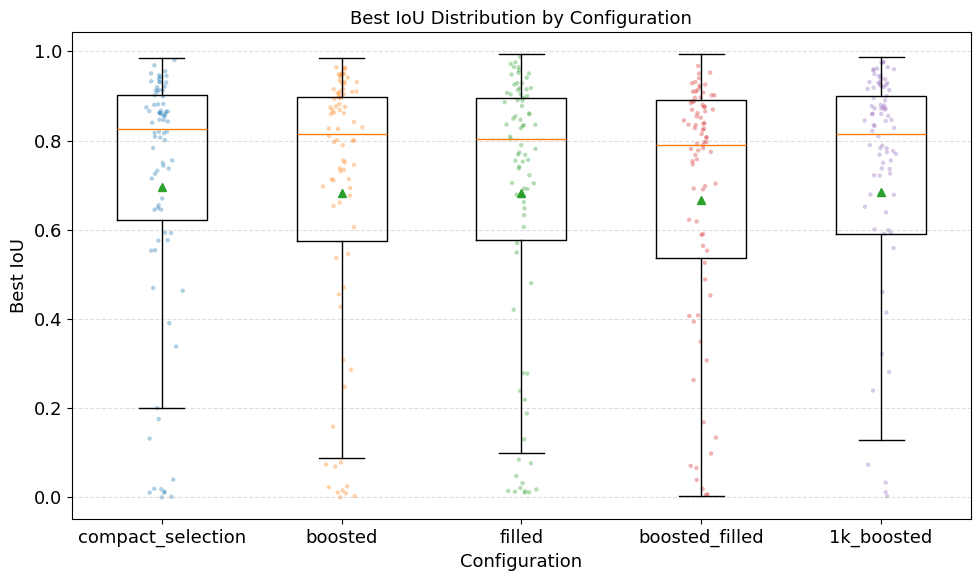

In [73]:
import matplotlib.pyplot as plt
import numpy as np

# Numero di punti da mostrare per ogni configurazione
SAMPLE_SIZE = 80

data = [
    gt_base_SAM[param_toCompare],
    gt_boosted[param_toCompare],
    gt_filled[param_toCompare],
    gt_boosted_filled[param_toCompare],
    gt_1k_boosted[param_toCompare],
]

labels = [
    "compact_selection",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted",
]

plt.figure(figsize=(10, 6))

# Boxplot senza visualizzazione automatica degli outlier
plt.boxplot(
    data,
    tick_labels=labels,
    showmeans=True,
    showfliers=False,
)

# Campione dei punti reali
rng = np.random.default_rng(42)

for i, values in enumerate(data, start=1):

    values = np.asarray(values)
    values = values[~np.isnan(values)]

    n_sample = min(SAMPLE_SIZE, len(values))

    sampled_values = rng.choice(
        values,
        size=n_sample,
        replace=False
    )

    # Piccolo jitter orizzontale
    x = rng.normal(
        loc=i,
        scale=0.04,
        size=n_sample
    )

    plt.scatter(
        x,
        sampled_values,
        s=10,
        alpha=0.35,
        edgecolors="none"
    )

plt.ylabel("Best IoU")
plt.xlabel("Configuration")
plt.title("Best IoU Distribution by Configuration")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gt_iou_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

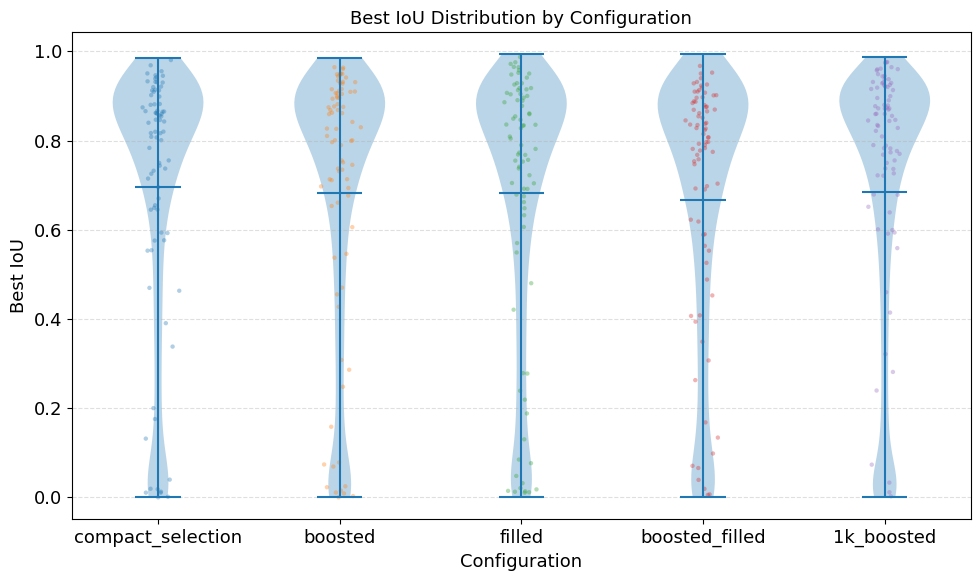

In [74]:
import matplotlib.pyplot as plt
import numpy as np

# Numero di punti da mostrare per ogni configurazione
SAMPLE_SIZE = 80

data = [
    gt_base_SAM[param_toCompare],
    gt_boosted[param_toCompare],
    gt_filled[param_toCompare],
    gt_boosted_filled[param_toCompare],
    gt_1k_boosted[param_toCompare],
]

labels = [
    "compact_selection",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted",
]

plt.figure(figsize=(10, 6))

# Violin plot
plt.violinplot(
    data,
    showmeans=True,
)

# Campione dei punti reali
rng = np.random.default_rng(42)

for i, values in enumerate(data, start=1):

    values = np.asarray(values)
    values = values[~np.isnan(values)]

    n_sample = min(SAMPLE_SIZE, len(values))

    sampled_values = rng.choice(
        values,
        size=n_sample,
        replace=False
    )

    # Piccolo jitter orizzontale
    x = rng.normal(
        loc=i,
        scale=0.04,
        size=n_sample
    )

    plt.scatter(
        x,
        sampled_values,
        s=10,
        alpha=0.35,
        edgecolors="none"
    )

# Etichette asse X
plt.xticks(
    range(1, len(labels) + 1),
    labels
)

plt.ylabel("Best IoU")
plt.xlabel("Configuration")
plt.title("Best IoU Distribution by Configuration")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gt_iou_distribution_violin.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

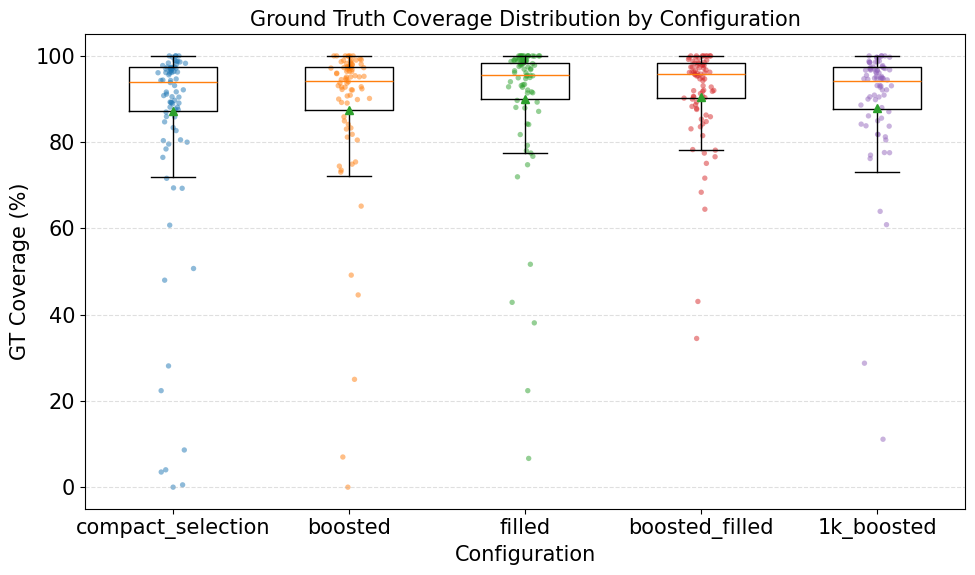

In [75]:
import matplotlib.pyplot as plt
import numpy as np

param_toCompare = "gt_coverage"
FONT_SIZE = 15

# Numero di punti da mostrare per ogni configurazione
SAMPLE_SIZE = 80

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

data = [
    gt_base_SAM[param_toCompare],
    gt_boosted[param_toCompare],
    gt_filled[param_toCompare],
    gt_boosted_filled[param_toCompare],
    gt_1k_boosted[param_toCompare],
]

labels = [
    "compact_selection",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted",
]

plt.figure(figsize=(10, 6))

# Boxplot senza visualizzazione automatica degli outlier
plt.boxplot(
    data,
    tick_labels=labels,
    showmeans=True,
    showfliers=False,
)

# Campione dei punti reali
rng = np.random.default_rng(42)

for i, values in enumerate(data, start=1):

    values = np.asarray(values)
    values = values[~np.isnan(values)]

    n_sample = min(SAMPLE_SIZE, len(values))

    sampled_values = rng.choice(
        values,
        size=n_sample,
        replace=False
    )

    # Piccolo jitter orizzontale
    x = rng.normal(
        loc=i,
        scale=0.04,
        size=n_sample
    )

    plt.scatter(
        x,
        sampled_values,
        s=15,
        alpha=0.50,
        edgecolors="none"
    )

plt.ylabel("GT Coverage (%)")
plt.xlabel("Configuration")
plt.title("Ground Truth Coverage Distribution by Configuration")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gt_coverage_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

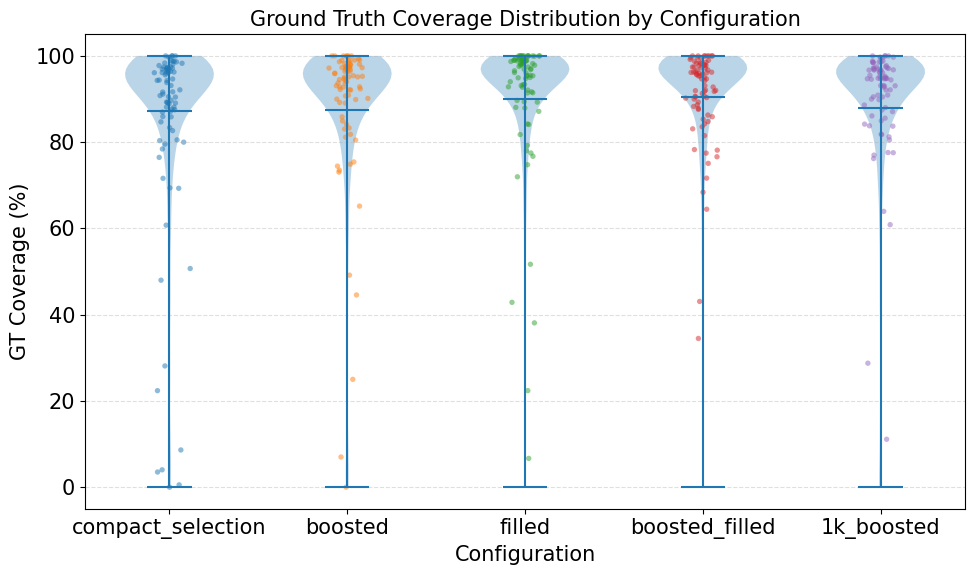

In [76]:
import matplotlib.pyplot as plt
import numpy as np

param_toCompare = "gt_coverage"
FONT_SIZE = 15

# Numero di punti da mostrare per ogni configurazione
SAMPLE_SIZE = 80

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

data = [
    gt_base_SAM[param_toCompare],
    gt_boosted[param_toCompare],
    gt_filled[param_toCompare],
    gt_boosted_filled[param_toCompare],
    gt_1k_boosted[param_toCompare],
]

labels = [
    "compact_selection",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted",
]

plt.figure(figsize=(10, 6))

# Violin plot
plt.violinplot(
    data,
    showmeans=True,
)

# Campione dei punti reali
rng = np.random.default_rng(42)

for i, values in enumerate(data, start=1):

    values = np.asarray(values)
    values = values[~np.isnan(values)]

    n_sample = min(SAMPLE_SIZE, len(values))

    sampled_values = rng.choice(
        values,
        size=n_sample,
        replace=False
    )

    # Piccolo jitter orizzontale
    x = rng.normal(
        loc=i,
        scale=0.04,
        size=n_sample
    )

    plt.scatter(
        x,
        sampled_values,
        s=15,
        alpha=0.50,
        edgecolors="none"
    )

# Etichette delle configurazioni
plt.xticks(
    range(1, len(labels) + 1),
    labels
)

plt.ylabel("GT Coverage (%)")
plt.xlabel("Configuration")
plt.title("Ground Truth Coverage Distribution by Configuration")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gt_coverage_distribution_violin.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

## PLOTS

In [77]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

FONT_SIZE = 20

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

def plot_all_gt_config_subsets(image_id, grid_df, coco):

    configs = [
        ("base_SAM", "COMPACT SELECTION"),
        ("boosted", "BOOSTED"),
        ("filled", "FILLED"),
        ("boosted_filled", "BOOSTED + FILLED"),
        ("1k_boosted", "1K BOOSTED"),
    ]

    # --------------------------------------------------------
    # Ground Truth COCO
    # --------------------------------------------------------
    ann_ids = coco.getAnnIds(
        imgIds=[int(image_id)],
        iscrowd=False
    )

    annotations = coco.loadAnns(ann_ids)

    if len(annotations) == 0:
        print("Nessun Ground Truth trovato.")
        return

    # Prendo la shape da una qualsiasi configurazione
    first_row = grid_df[
        grid_df["image_id"] == image_id
    ].iloc[0]

    example_partition = np.load(
        first_row["mask_path"]
    )

    h, w = example_partition.shape

    # --------------------------------------------------------
    # GT label map
    # --------------------------------------------------------
    gt_labels = np.zeros(
        (h, w),
        dtype=np.int32
    )

    gt_masks = []
    gt_names = []

    for gt_id, ann in enumerate(
        annotations,
        start=1
    ):
        gt_mask = coco.annToMask(
            ann
        ).astype(bool)

        gt_masks.append(gt_mask)

        category = coco.loadCats(
            [ann["category_id"]]
        )[0]["name"]

        gt_names.append(category)

        gt_labels[gt_mask] = gt_id

    n_gt = len(gt_masks)

    # --------------------------------------------------------
    # Colormap comune GT / subset
    # --------------------------------------------------------
    gray_values = np.linspace(
        0.25,
        1.0,
        max(n_gt, 1)
    )

    colors = np.vstack([
        [0, 0, 0, 1],
        np.column_stack([
            gray_values,
            gray_values,
            gray_values,
            np.ones_like(gray_values)
        ])
    ])

    gt_cmap = ListedColormap(colors)

    # --------------------------------------------------------
    # Plot: 5 configurazioni x 4 colonne
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        5,
        4,
        figsize=(22, 25),
        constrained_layout=True
    )

    for row_idx, (config, title) in enumerate(configs):

        row = grid_df[
            (grid_df["image_id"] == image_id)
            &
            (grid_df["config"] == config)
        ]

        if row.empty:
            for col in range(4):
                axes[row_idx, col].axis("off")
            continue

        partition = np.load(
            row.iloc[0]["mask_path"]
        )

        # ----------------------------------------------------
        # Subset label map
        # ----------------------------------------------------
        subset_labels = np.zeros(
            partition.shape,
            dtype=np.int32
        )

        iou_values = []

        for gt_id, gt_mask in enumerate(
            gt_masks,
            start=1
        ):
            best_iou, selected_ids = maximize_iou(
                gt_mask,
                partition
            )

            iou_values.append(best_iou)

            selected_mask = np.isin(
                partition,
                selected_ids
            )

            subset_labels[selected_mask] = gt_id

        # ----------------------------------------------------
        # MASKS -> GT
        # ----------------------------------------------------
        masks_to_gt_labels = np.zeros(
            partition.shape,
            dtype=np.int32
        )

        mask_ids = np.unique(partition)
        mask_ids = mask_ids[mask_ids != 0]

        for mask_id in mask_ids:

            current_mask = partition == mask_id

            best_gt_id = 0
            best_iou = 0.0

            for gt_id, gt_mask in enumerate(
                gt_masks,
                start=1
            ):
                intersection = np.count_nonzero(
                    current_mask & gt_mask
                )

                union = np.count_nonzero(
                    current_mask | gt_mask
                )

                iou = (
                    intersection / union
                    if union > 0
                    else 0.0
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_id = gt_id

            if best_gt_id != 0:
                masks_to_gt_labels[
                    current_mask
                ] = best_gt_id

        # ----------------------------------------------------
        # 1. Ground Truth
        # ----------------------------------------------------
        axes[row_idx, 0].imshow(
            gt_labels,
            cmap=gt_cmap,
            vmin=0,
            vmax=n_gt,
            interpolation="nearest"
        )

        axes[row_idx, 0].set_title(
            f"Ground Truth\n{n_gt} instances"
        )

        axes[row_idx, 0].set_xticks([])
        axes[row_idx, 0].set_yticks([])

        # ----------------------------------------------------
        # 2. Partition
        # ----------------------------------------------------
        axes[row_idx, 1].imshow(
            partition,
            cmap="turbo",
            interpolation="nearest"
        )

        axes[row_idx, 1].set_title(
            f"{title}\n"
            f"{len(np.unique(partition)) - 1} instances"
        )

        axes[row_idx, 1].set_xticks([])
        axes[row_idx, 1].set_yticks([])

        # ----------------------------------------------------
        # 3. Optimal subsets
        # ----------------------------------------------------
        axes[row_idx, 2].imshow(
            subset_labels,
            cmap=gt_cmap,
            vmin=0,
            vmax=n_gt,
            interpolation="nearest"
        )

        mean_iou = np.mean(iou_values)

        axes[row_idx, 2].set_title(
            f"Optimal subsets\n"
            f"Mean IoU = {mean_iou:.4f}"
        )

        axes[row_idx, 2].set_xticks([])
        axes[row_idx, 2].set_yticks([])

        # ----------------------------------------------------
        # 4. MASKS -> GT
        # ----------------------------------------------------
        axes[row_idx, 3].imshow(
            masks_to_gt_labels,
            cmap=gt_cmap,
            vmin=0,
            vmax=n_gt,
            interpolation="nearest"
        )

        axes[row_idx, 3].set_title(
            "MASKS → GT"
        )

        axes[row_idx, 3].set_xticks([])
        axes[row_idx, 3].set_yticks([])

        # Bordo
        for col in range(4):
            ax = axes[row_idx, col]

            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_color("black")
                spine.set_linewidth(0.75)

    fig.suptitle(
        f"Image {image_id}",
        fontsize=FONT_SIZE
    )

    plt.savefig(
        f"/kaggle/working/{image_id}.svg",
        format="svg",
        bbox_inches="tight"
    )

    plt.show()

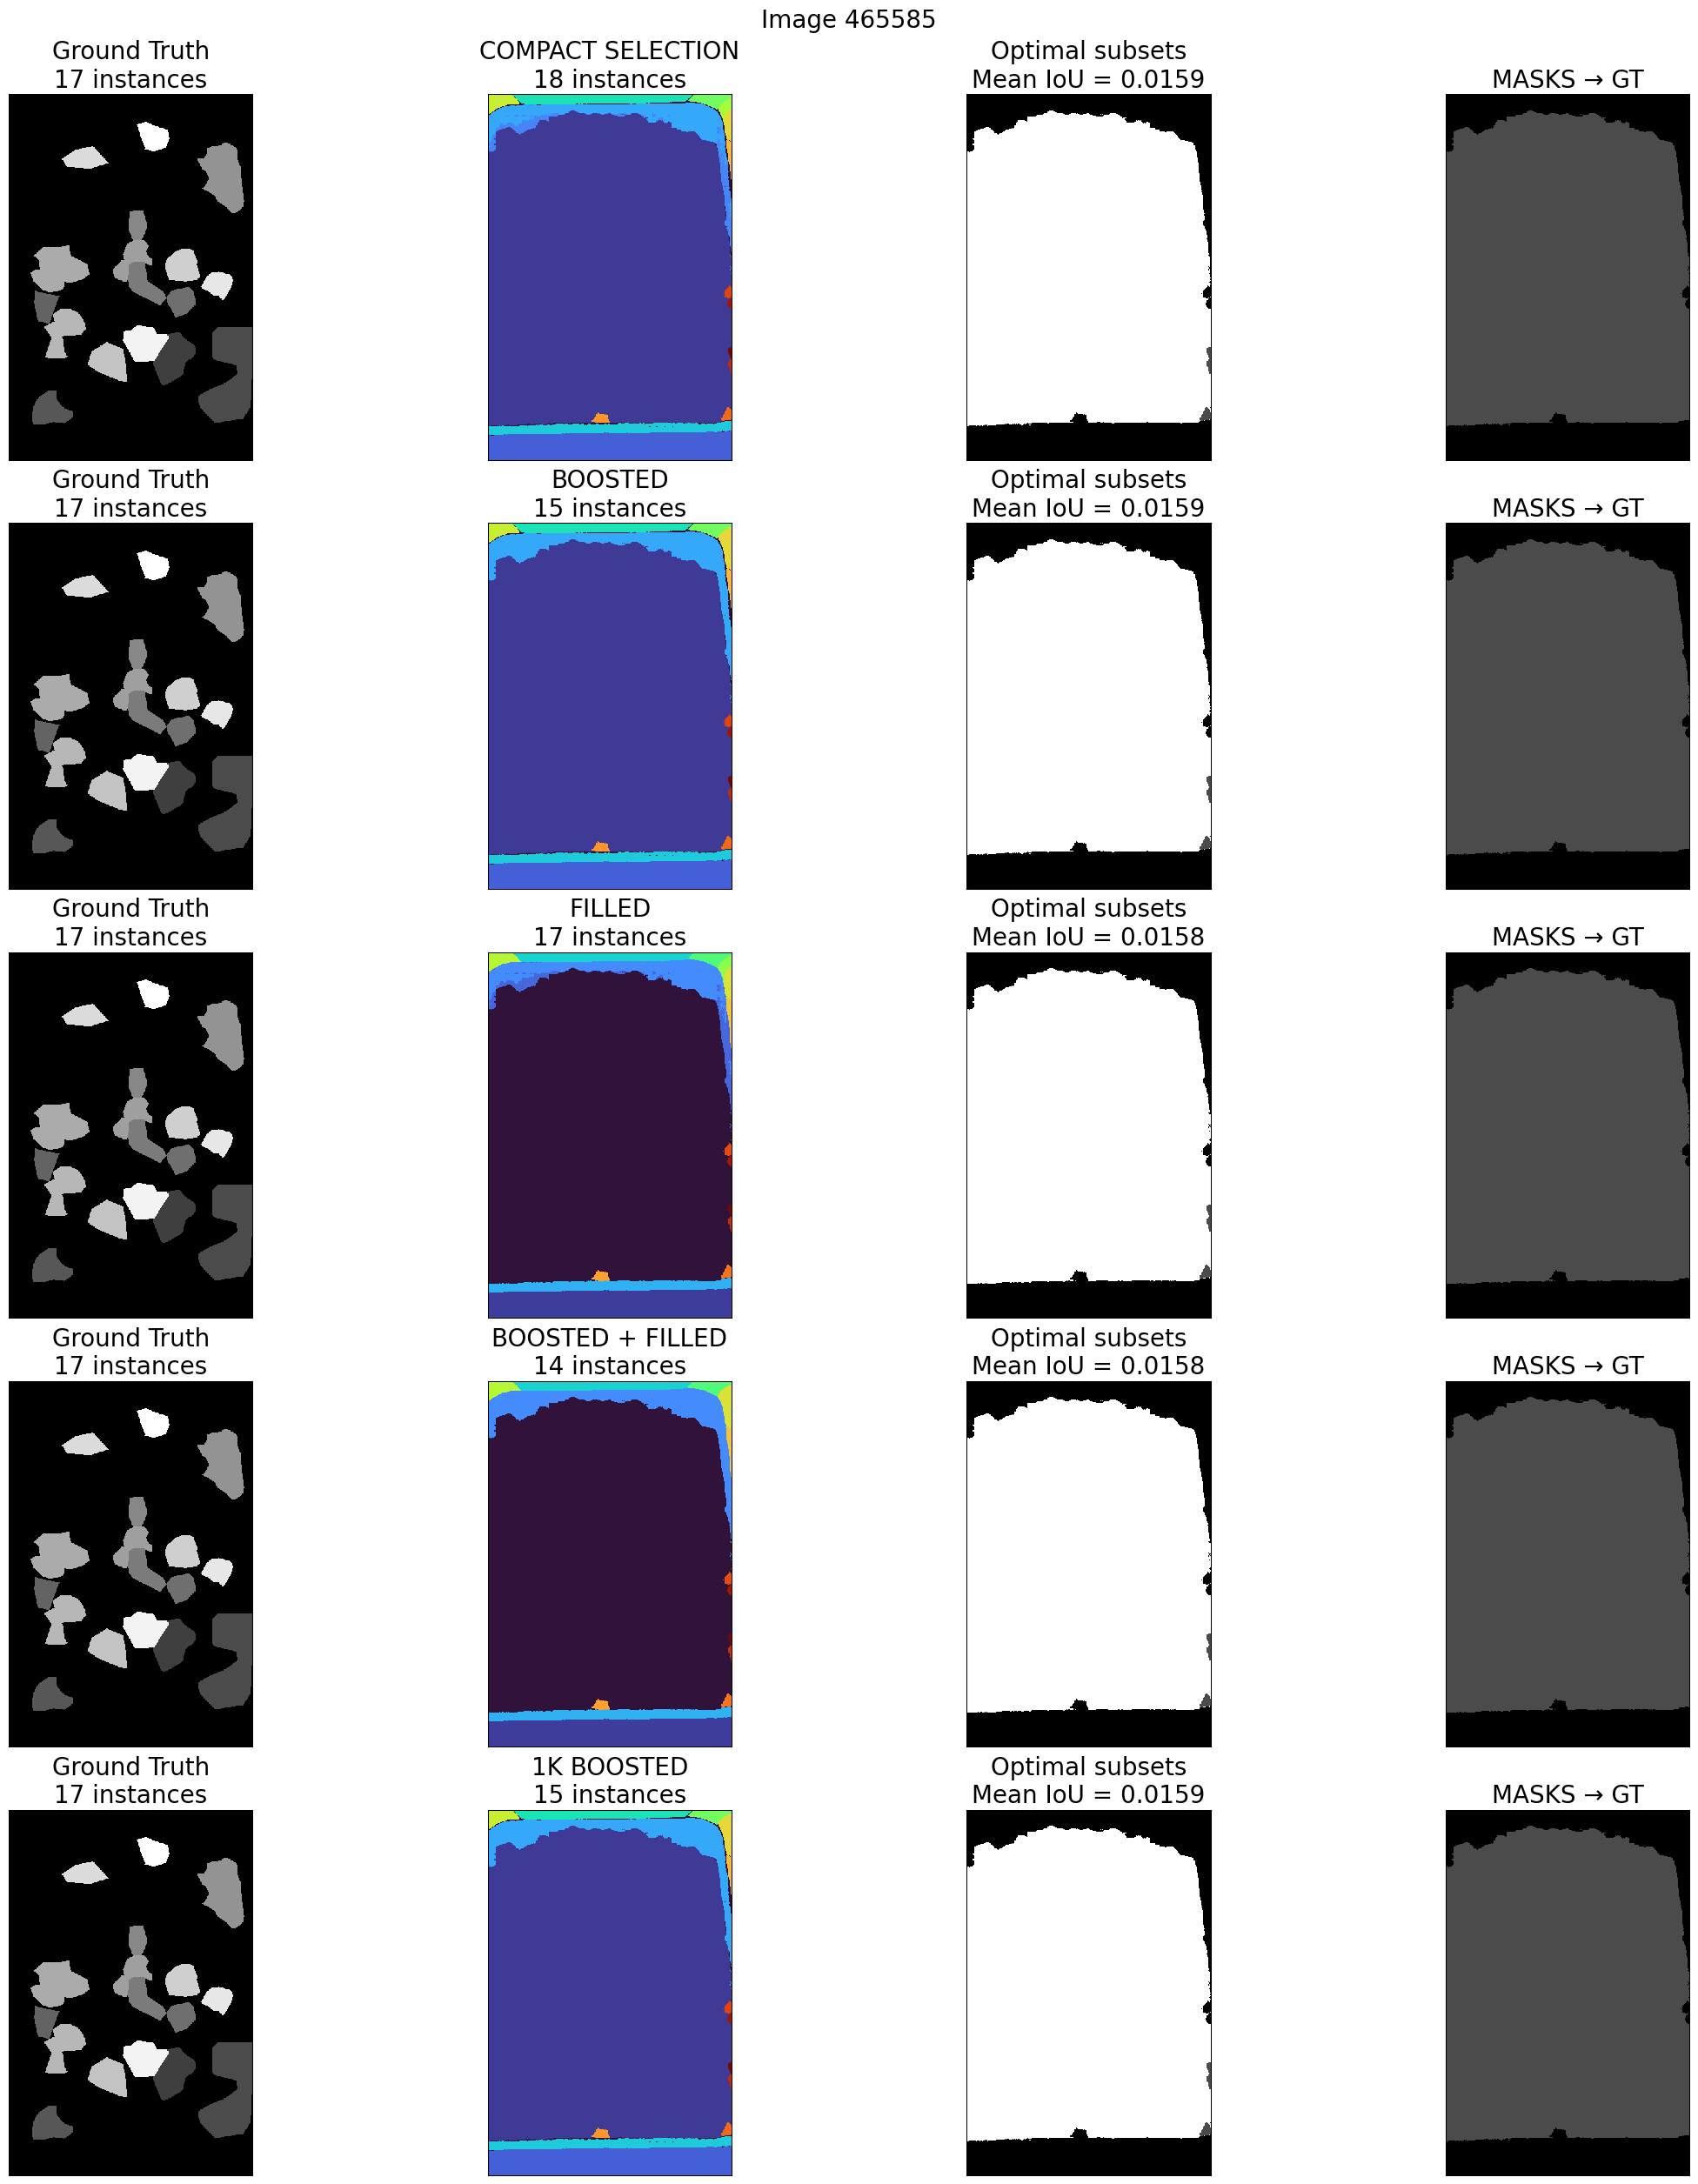

In [78]:
plot_all_gt_config_subsets(
    #image_id=537241,
    #image_id=785,
    image_id=465585,
    grid_df=grid_df,
    coco=coco
)

In [79]:
image_iou = (
    gt_df
    .groupby("image_id")["best_iou"]
    .mean()
)

best_image_id = image_iou.idxmax()
worst_image_id = image_iou.idxmin()

print("Best image ID:", best_image_id)
print("Mean IoU:", image_iou.loc[best_image_id])

print()

print("Worst image ID:", worst_image_id)
print("Mean IoU:", image_iou.loc[worst_image_id])

Best image ID: 153568
Mean IoU: 0.9876837795443065

Worst image ID: 402334
Mean IoU: 0.007700855181726116


## ANOVA FOR GT

In [80]:
from statsmodels.stats.anova import AnovaRM

# One observation per image_id × config
anova_df = (
    gt_df
    .groupby(["image_id", "config", "gt_index"], as_index=False)["best_iou"]
    .mean()
)
anova_df["uid"] = anova_df.image_id * 100 + anova_df.gt_index

anova_df.head(10)

,image_id,config,gt_index,best_iou,uid
0,785,1k_boosted,0,0.930272,78500
1,785,1k_boosted,1,0.399125,78501
2,785,base_SAM,0,0.932053,78500
3,785,base_SAM,1,0.577246,78501
4,785,boosted,0,0.930272,78500
5,785,boosted,1,0.399125,78501
6,785,boosted_filled,0,0.917609,78500
7,785,boosted_filled,1,0.400199,78501
8,785,filled,0,0.919596,78500
9,785,filled,1,0.579241,78501


In [81]:
from statsmodels.stats.anova import AnovaRM

comparisons = [
    # Confronti originali
    ("Base", "Boosting", "base_SAM", "boosted"),
    ("Base", "Filling", "base_SAM", "filled"),
    ("Base", "Boosting + Filling", "base_SAM", "boosted_filled"),
    ("Boosting", "Filling", "boosted", "filled"),
    ("Boosting", "Boosting + Filling", "boosted", "boosted_filled"),
    ("Filling", "Boosting + Filling", "filled", "boosted_filled"),

    # Confronti con 1k_boosted
    ("Base", "1k_boosted", "base_SAM", "1k_boosted"),
    ("Filling", "1k_boosted", "filled", "1k_boosted"),
    ("Boosting + Filling", "1k_boosted", "boosted_filled", "1k_boosted"),
]

anova_results = []

for name_1, name_2, config_1, config_2 in comparisons:

    subset = anova_df[
        anova_df["config"].isin([config_1, config_2])
    ].copy()

    # Mantiene solo i GT presenti in entrambe le configurazioni
    valid_uids = (
        subset.groupby("uid")["config"]
        .nunique()
    )

    valid_uids = valid_uids[
        valid_uids == 2
    ].index

    subset = subset[
        subset["uid"].isin(valid_uids)
    ]

    result = AnovaRM(
        data=subset,
        depvar="best_iou",
        subject="uid",
        within=["config"]
    ).fit()

    table = result.anova_table.loc["config"]

    anova_results.append({
        "Config 1": name_1,
        "Config 2": name_2,
        "N": len(valid_uids),
        "F": table["F Value"],
        "Num DF": table["Num DF"],
        "Den DF": table["Den DF"],
        "p-value": table["Pr > F"]
    })

In [82]:
import pandas as pd

anova_table = pd.DataFrame(anova_results)

anova_table["Significant"] = anova_table["p-value"] < 0.05

anova_table.style.format({
    "F": "{:.4f}",
    "Num DF": "{:.0f}",
    "Den DF": "{:.0f}",
    "p-value": "{:E}"
})

,Config 1,Config 2,N,F,Num DF,Den DF,p-value,Significant
0,Base,Boosting,2431,204.1505,1,2430,1.569070E-44,True
1,Base,Filling,2431,147.9111,1,2430,4.445566E-33,True
2,Base,Boosting + Filling,2431,396.3188,1,2430,8.175754E-82,True
3,Boosting,Filling,2431,0.9107,1,2430,3.400236E-01,False
4,Boosting,Boosting + Filling,2431,199.9005,1,2430,1.126862E-43,True
5,Filling,Boosting + Filling,2431,248.2574,1,2430,2.482505E-53,True
6,Base,1k_boosted,2431,204.1505,1,2430,1.569070E-44,True
7,Filling,1k_boosted,2431,0.9107,1,2430,3.400236E-01,False
8,Boosting + Filling,1k_boosted,2431,199.9005,1,2430,1.126862E-43,True


## valutazione qualitativa

In [83]:
thresholds = [0.50, 0.75, 0.90]

configs = {
    "Base": gt_base_SAM,
    "Boosting": gt_boosted,
    "Filling": gt_filled,
    "Boosting + Filling": gt_boosted_filled,
    "1k_boosted": gt_1k_boosted,
}

results = []

for config_name, data in configs.items():
    n = len(data)

    row = {
        "Configuration": config_name,
        "Total annotations": n,
    }

    for threshold in thresholds:
        count = (data["best_iou"] >= threshold).sum()
        percentage = count / n * 100

        row[f"IoU >= {threshold}"] = count
        row[f"IoU >= {threshold} (%)"] = percentage

    results.append(row)

iou_thresholds_table = pd.DataFrame(results)

iou_thresholds_table

,Configuration,Total annotations,IoU >= 0.5,IoU >= 0.5 (%),IoU >= 0.75,IoU >= 0.75 (%),IoU >= 0.9,IoU >= 0.9 (%)
0,Base,2431,1928,79.308926,1521,62.566845,630,25.915261
1,Boosting,2431,1897,78.033731,1461,60.098725,592,24.352118
2,Filling,2431,1911,78.609626,1422,58.494447,579,23.817359
3,Boosting + Filling,2431,1870,76.923077,1361,55.985191,540,22.213081
4,1k_boosted,7251,5697,78.568473,4434,61.150186,1800,24.824162


In [84]:
iou_thresholds_percentage = pd.DataFrame({
    "Configuration": list(configs.keys()),
    "IoU MEAN": [
        (data["best_iou"]).mean() * 100
        for data in configs.values()
    ],
})

iou_thresholds_percentage

,Configuration,IoU MEAN
0,Base,69.487917
1,Boosting,68.148914
2,Filling,68.277752
3,Boosting + Filling,66.761867
4,1k_boosted,68.527554


# KRUSKAL

In [85]:
!pip install scikit-posthocs -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.8 MB/s eta 0:00:00


### Coverage

In [86]:
import pandas as pd
import scipy.stats as stats
import scikit_posthocs as sp

configs = [
    "base_SAM",
    "boosted",
    "filled",
    "boosted_filled",
    "1k_boosted"
]

config_labels = {
    "base_SAM": "Compact Selection",
    "boosted": "Boosting",
    "filled": "Filling",
    "boosted_filled": "Boosting + Filling",
    "1k_boosted": "1k Boosted"
}


def statistical_test(
    data,
    value_col,
    config_col="config",
    metric_name="Metric",
    test="kruskal"
):
    """
    Esegue uno dei due test:

    test="kruskal":
        Kruskal-Wallis + Dunn post-hoc con Bonferroni

    test="anova":
        One-way ANOVA + Tukey HSD
    """

    temp = data[
        data[config_col].isin(configs)
    ][[config_col, value_col]].dropna().copy()

    groups = [
        temp.loc[
            temp[config_col] == config,
            value_col
        ].values
        for config in configs
    ]

    # =========================================================
    # KRUSKAL-WALLIS + DUNN
    # =========================================================
    if test == "kruskal":

        statistic, p = stats.kruskal(*groups)

        print(f"\n{'=' * 60}")
        print(f"Kruskal-Wallis - {metric_name}")
        print(f"H = {statistic:.4f}")
        print(f"p-value = {p:.6g}")
        print("Significativo:", "Sì" if p < 0.05 else "No")

        # Dunn post-hoc
        dunn = sp.posthoc_dunn(
            temp,
            val_col=value_col,
            group_col=config_col,
            p_adjust="bonferroni"
        )

        rows = []

        for i in range(len(configs)):
            for j in range(i + 1, len(configs)):

                c1 = configs[i]
                c2 = configs[j]

                # Esclude Boosting vs 1k Boosted
                if {c1, c2} == {"boosted", "1k_boosted"}:
                    continue

                p_pair = dunn.loc[c1, c2]

                rows.append({
                    "Configurazione 1": config_labels[c1],
                    "Configurazione 2": config_labels[c2],
                    "p-value": p_pair,
                    "Significativo": "Sì" if p_pair < 0.05 else "No"
                })

        pairwise_df = pd.DataFrame(rows)

        print("\nDunn post-hoc con correzione Bonferroni")
        display(pairwise_df)


    # =========================================================
    # ONE-WAY ANOVA + TUKEY
    # =========================================================
    elif test == "anova":

        statistic, p = stats.f_oneway(*groups)

        print(f"\n{'=' * 60}")
        print(f"One-way ANOVA - {metric_name}")
        print(f"F = {statistic:.4f}")
        print(f"p-value = {p:.6g}")
        print("Significativo:", "Sì" if p < 0.05 else "No")

        # Tukey HSD
        tukey = stats.tukey_hsd(*groups)

        rows = []

        for i in range(len(configs)):
            for j in range(i + 1, len(configs)):

                c1 = configs[i]
                c2 = configs[j]

                # Esclude Boosting vs 1k Boosted
                if {c1, c2} == {"boosted", "1k_boosted"}:
                    continue

                p_pair = tukey.pvalue[i, j]

                rows.append({
                    "Configurazione 1": config_labels[c1],
                    "Configurazione 2": config_labels[c2],
                    "p-value": p_pair,
                    "Significativo": "Sì" if p_pair < 0.05 else "No"
                })

        pairwise_df = pd.DataFrame(rows)

        print("\nTukey HSD post-hoc")
        display(pairwise_df)

    else:
        raise ValueError(
            "test deve essere 'kruskal' oppure 'anova'"
        )

    return {
        "test": test,
        "statistic": statistic,
        "p_value": p,
        "pairwise": pairwise_df
    }

### SAM Coverage

In [87]:
sam_coverage_results = statistical_test(
    data=df,
    value_col="coverage",
    metric_name="SAM Coverage",
    test="kruskal"
)


Kruskal-Wallis - SAM Coverage
H = 1015.3287
p-value = 1.70058e-218
Significativo: Sì

Dunn post-hoc con correzione Bonferroni


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,1.000000e+00,No
1,Compact Selection,Filling,2.179749e-77,Sì
2,Compact Selection,Boosting + Filling,2.179749e-77,Sì
3,Compact Selection,1k Boosted,1.000000e+00,No
4,Boosting,Filling,2.179749e-77,Sì
5,Boosting,Boosting + Filling,2.179749e-77,Sì
6,Filling,Boosting + Filling,1.000000e+00,No
7,Filling,1k Boosted,2.540163e-117,Sì
8,Boosting + Filling,1k Boosted,2.540163e-117,Sì


In [88]:
sam_coverage_results = statistical_test(
    data=df,
    value_col="coverage",
    metric_name="SAM Coverage",
    test="anova"
)


One-way ANOVA - SAM Coverage
F = 103.8552
p-value = 4.25855e-81
Significativo: Sì

Tukey HSD post-hoc


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,1.000000e+00,No
1,Compact Selection,Filling,1.057154e-12,Sì
2,Compact Selection,Boosting + Filling,1.057154e-12,Sì
3,Compact Selection,1k Boosted,9.321866e-01,No
4,Boosting,Filling,1.057154e-12,Sì
5,Boosting,Boosting + Filling,1.057154e-12,Sì
6,Filling,Boosting + Filling,1.000000e+00,No
7,Filling,1k Boosted,1.057154e-12,Sì
8,Boosting + Filling,1k Boosted,1.057154e-12,Sì


### GT Coverage

In [89]:
gt_coverage_results = statistical_test(
    data=gt_df,
    value_col="gt_coverage",
    metric_name="GT Coverage",
    test="kruskal"    
)


Kruskal-Wallis - GT Coverage
H = 180.0818
p-value = 7.16089e-38
Significativo: Sì

Dunn post-hoc con correzione Bonferroni


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,1.000000e+00,No
1,Compact Selection,Filling,6.722839e-15,Sì
2,Compact Selection,Boosting + Filling,1.566066e-20,Sì
3,Compact Selection,1k Boosted,1.000000e+00,No
4,Boosting,Filling,1.015237e-11,Sì
5,Boosting,Boosting + Filling,9.209087e-17,Sì
6,Filling,Boosting + Filling,1.000000e+00,No
7,Filling,1k Boosted,1.003316e-15,Sì
8,Boosting + Filling,1k Boosted,6.429667e-23,Sì


In [90]:
gt_coverage_results = statistical_test(
    data=gt_df,
    value_col="gt_coverage",
    metric_name="GT Coverage",
    test="anova"    
)


One-way ANOVA - GT Coverage
F = 17.9715
p-value = 9.74742e-15
Significativo: Sì

Tukey HSD post-hoc


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,9.866175e-01,No
1,Compact Selection,Filling,4.618035e-07,Sì
2,Compact Selection,Boosting + Filling,8.077698e-09,Sì
3,Compact Selection,1k Boosted,4.532470e-01,No
4,Boosting,Filling,7.074719e-06,Sì
5,Boosting,Boosting + Filling,1.734407e-07,Sì
6,Filling,Boosting + Filling,9.609168e-01,No
7,Filling,1k Boosted,5.120939e-06,Sì
8,Boosting + Filling,1k Boosted,4.888219e-08,Sì


### GT IoU

In [91]:
iou_results = statistical_test(
    data=gt_df,
    value_col="best_iou",
    metric_name="Best IoU",
    test="kruskal"
)


Kruskal-Wallis - Best IoU
H = 22.2144
p-value = 0.000181652
Significativo: Sì

Dunn post-hoc con correzione Bonferroni


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,0.646972,No
1,Compact Selection,Filling,0.142273,No
2,Compact Selection,Boosting + Filling,0.000102,Sì
3,Compact Selection,1k Boosted,0.992898,No
4,Boosting,Filling,1.000000,No
5,Boosting,Boosting + Filling,0.102759,No
6,Filling,Boosting + Filling,0.497306,No
7,Filling,1k Boosted,1.000000,No
8,Boosting + Filling,1k Boosted,0.001744,Sì


In [92]:
iou_results = statistical_test(
    data=gt_df,
    value_col="best_iou",
    metric_name="Best IoU",
    test="anova"
)


One-way ANOVA - Best IoU
F = 2.7063
p-value = 0.0286361
Significativo: Sì

Tukey HSD post-hoc


,Configurazione 1,Configurazione 2,p-value,Significativo
0,Compact Selection,Boosting,0.518627,No
1,Compact Selection,Filling,0.617066,No
2,Compact Selection,Boosting + Filling,0.012393,Sì
3,Compact Selection,1k Boosted,0.643388,No
4,Boosting,Filling,0.999884,No
5,Boosting,Boosting + Filling,0.482310,No
6,Filling,Boosting + Filling,0.388757,No
7,Filling,1k Boosted,0.996500,No
8,Boosting + Filling,1k Boosted,0.084291,No


In [93]:
# gt_df